**HINESHA**

**Importing necessary libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print(np.version)

<module 'numpy.version' from 'C:\\Users\\HP\\anaconda3\\Lib\\site-packages\\numpy\\version.py'>


**Loading the dataset**

In [4]:
df = pd.read_csv("amazon.csv")
df.head(3)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


In [6]:
df.shape

(1465, 16)

**Handling null**

In [9]:
# Checking for null values
df.isnull().sum()

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

In [11]:
# Filling the null values of 'rating_count' column with 0
df['rating_count'] = df['rating_count'].fillna(0) 

In [13]:
df.isnull().sum()

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

**Handling duplicates**

In [16]:
# Total number of rows with non-null user_id
total_user_count = df['user_id'].count()  

# Number of unique user_ids
unique_user_count = df['user_id'].nunique()  

# Number of non-unique user_ids
non_unique_user_count = total_user_count - unique_user_count 

print(f"Number of Total Users : {total_user_count}")
print(f"Number of unique user IDs : {unique_user_count}")
print(f"Number of non unique users : {non_unique_user_count}")

# CONCLUSION --> (Number of Total Users : 1465) each row has user_IDs 

Number of Total Users : 1465
Number of unique user IDs : 1194
Number of non unique users : 271


In [18]:
# handling duplicate user IDs
duplicate_user_ids = df['user_id'][df['user_id'].duplicated()].unique()
print(duplicate_user_ids)

# Duplicate user IDs imply that the same user has reviewed multiple products
# Identifying duplicate users can be helpful for collaborative filtering

['AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBXNGXZJT525AQ,AHONIZU3ICIEHQIGQ6R2VFRSBXOQ,AFPHD2CRPDZMWMBL7WXRSVYWS5JA,AEZ346GX3HJ4O4XNRPHCNHXQURMQ,AEPSWFPNECKO34PUC7I56ITGXR6Q,AHWVEHR5DYLVFTO2KF3IZATFQSWQ,AH4QT33M55677I7ISQOAKEQWACYQ'
 'AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5SGCUQBP7YSCA,AH725ST5NW2Y4JZPKUNTIJCUK2BA,AHV3TXIFCJPMS4D5JATCEUR266MQ,AGWIGDEMFIIUAOXYY2QATNBSUGHA,AFSTSLQUV4EVEXWKBOLEFHL2H5YQ,AGAKDNBHY2FKX7I4ACRGILU7QL7A,AFNWJUWJRHCC6HN52KMG5AKZY37Q'
 'AEQ2YMXSZWEOHK2EHTNLOS56YTZQ,AGRVINWECNY7323CWFXZYYIZOFTQ,AHBAT6VLOXWGYDL57KHCNCLPXAKA,AF7NDY2H6JVYTSQOZP76GCATQ34Q,AFV7ZA733ZLME4KNLZPMPCBUNPPA,AHFAAPSY2MJ5HYOU2VQDJ7AQY4NQ,AH2WGV2PEBUTICRPBEEVKF24G5LA,AEP4MK3EKOBDKTGPJTRN5RBDIODA'
 'AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBBSNLYT3ONILA,AHCTC6ULH4XB6YHDY6PCH2R772LQ,AGYHHIERNXKA6P5T7CZLXKVPT7IQ,AG4OGOFWXJZTQ2HKYIOCOY3KXF2Q,AENGU523SXMOS7JPDTW52PNNVWGQ,AEQJHCVTNINBS4FKTBGQRQTGTE5Q,AFC3FFC5PKFF5PMA52S3VCHOZ5FQ'
 'AHIKJUDTVJ4T6DV6IUGFYZ5LXMPA,AE55KTFVNXYFD5FPYWP2OUPEYNPQ,

**Splitting and Exploding Review Data with Missing Value Handling**

In [21]:
# a row with multiple users (seperated by commas) in the user_id field will be stored as a list instead of a single string

In [23]:
# Ensure all relevant columns are split and missing values are hanlded
df['user_id'] = df['user_id'].str.split(',')
df['user_name'] = df['user_name'].str.split(',')
df['review_id'] = df['review_id'].str.split(',')
df['review_title'] = df['review_title'].str.split(',')
df['review_content'] = df['review_content'].str.split(',')

# Since there are multiple user IDs, review IDs, or review content entries in a single cell separated by commas
# splitting them into lists makes each individual entry accessible

In [25]:
# Ensure all columns have matching lengths, filling missing values with 'Not available'
columns_to_check = ['user_name', 'review_id', 'review_title', 'review_content']

for column in columns_to_check:
    df[column] = df.apply(lambda row: row[column] if len(row['user_id']) == len(row[column]) else ['Not available'] * len(row['user_id']), axis=1)

In [27]:
# Exploding all columns to create individual rows
# explode() --> takes lists in each row and creates new rows for each element in those lists
df_expanded = df.explode(['user_id', 'user_name', 'review_id', 'review_title', 'review_content']).fillna('Not available')

In [29]:
# Display the first few rows of the updated DataFrame
df_expanded[['user_id', 'user_name', 'review_id', 'review_title', 'review_content']].head(10)

,user_id,user_name,review_id,review_title,review_content
0,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,R3HXWT0LRP0NMF,Satisfied,Not available
0,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta,R2AJM3LFTLZHFO,Charging is really fast,Not available
0,AHCTC6ULH4XB6YHDY6PCH2R772LQ,Sundeep,R6AQJGUP6P86,Value for money,Not available
0,AGYHHIERNXKA6P5T7CZLXKVPT7IQ,S.Sayeed Ahmed,R1KD19VHEDV0OR,Product review,Not available
0,AG4OGOFWXJZTQ2HKYIOCOY3KXF2Q,jaspreet singh,R3C02RMYQMK6FC,Good quality,Not available
0,AENGU523SXMOS7JPDTW52PNNVWGQ,Khaja moin,R39GQRVBUZBWGY,Good product,Not available
0,AEQJHCVTNINBS4FKTBGQRQTGTE5Q,Anand,R2K9EDOE15QIRJ,Good Product,Not available
0,AFC3FFC5PKFF5PMA52S3VCHOZ5FQ,S.ARUMUGAM,R3OI7YT648TL8I,As of now seems good,Not available
1,AECPFYFQVRUWC3KGNLJIOREFP5LQ,ArdKn,RGIQEG07R9HS2,A Good Braided Cable for Your Type C Device,Not available
1,AGYYVPDD7YG7FYNBXNGXZJT525AQ,Nirbhay kumar,R1SMWZQ86XIN8U,Good quality product from ambrane,Not available


In [31]:
df = df_expanded.copy()
df.head(3)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,R3HXWT0LRP0NMF,Satisfied,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta,R2AJM3LFTLZHFO,Charging is really fast,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AHCTC6ULH4XB6YHDY6PCH2R772LQ,Sundeep,R6AQJGUP6P86,Value for money,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...


In [33]:
df.to_csv('username.csv', index=False)

In [35]:
# Checking for duplicates
df.duplicated().sum()

0

In [37]:
df_expanded.shape

(11503, 16)

In [39]:
df_expanded.head(10)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,R3HXWT0LRP0NMF,Satisfied,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta,R2AJM3LFTLZHFO,Charging is really fast,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AHCTC6ULH4XB6YHDY6PCH2R772LQ,Sundeep,R6AQJGUP6P86,Value for money,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AGYHHIERNXKA6P5T7CZLXKVPT7IQ,S.Sayeed Ahmed,R1KD19VHEDV0OR,Product review,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AG4OGOFWXJZTQ2HKYIOCOY3KXF2Q,jaspreet singh,R3C02RMYQMK6FC,Good quality,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AENGU523SXMOS7JPDTW52PNNVWGQ,Khaja moin,R39GQRVBUZBWGY,Good product,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AEQJHCVTNINBS4FKTBGQRQTGTE5Q,Anand,R2K9EDOE15QIRJ,Good Product,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AFC3FFC5PKFF5PMA52S3VCHOZ5FQ,S.ARUMUGAM,R3OI7YT648TL8I,As of now seems good,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4,"43,994","Compatible with all Type C enabled devices, be...",AECPFYFQVRUWC3KGNLJIOREFP5LQ,ArdKn,RGIQEG07R9HS2,A Good Braided Cable for Your Type C Device,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4,"43,994","Compatible with all Type C enabled devices, be...",AGYYVPDD7YG7FYNBXNGXZJT525AQ,Nirbhay kumar,R1SMWZQ86XIN8U,Good quality product from ambrane,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreak

In [41]:
df = df_expanded.copy()
df.shape

(11503, 16)

**Handling data types**

In [44]:
# just to check for what sort of data is there (numerical/categorical)
df.head(2)  

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,R3HXWT0LRP0NMF,Satisfied,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta,R2AJM3LFTLZHFO,Charging is really fast,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...


In [46]:
# Checking for the data types
df.dtypes

product_id             object
product_name           object
category               object
discounted_price       object
actual_price           object
discount_percentage    object
rating                 object
rating_count           object
about_product          object
user_id                object
user_name              object
review_id              object
review_title           object
review_content         object
img_link               object
product_link           object
dtype: object

In [48]:
# Object data type might not be efficient or suitable for certain operations
# especially when performing numerical computations, sorting, or building machine learning models

# Convert 'discounted_price' (if it contains currency symbols, remove them first)
df['discounted_price'] = df['discounted_price'].replace('[₹,]', '', regex=True)
df['discounted_price'] = pd.to_numeric(df['discounted_price'], errors='coerce')

# Convert 'actual_price' by removing currency symbols and commas, then convert to numeric
df['actual_price'] = df['actual_price'].replace('[₹,]', '', regex=True)
df['actual_price'] = pd.to_numeric(df['actual_price'], errors='coerce')

# Convert 'discount_percentage' by removing the '%' sign and converting to numeric
df['discount_percentage'] = df['discount_percentage'].str.replace('%', '', regex=False)
df['discount_percentage'] = pd.to_numeric(df['discount_percentage'], errors='coerce')

# Convert 'rating' to float
df['rating'] = pd.to_numeric(df['rating'], errors='coerce') 

# Convert 'rating_count' to integer
df['rating_count'] = pd.to_numeric(df['rating_count'], errors='coerce').fillna(0).astype(int)  

In [50]:
df.dtypes

product_id              object
product_name            object
category                object
discounted_price       float64
actual_price           float64
discount_percentage      int64
rating                 float64
rating_count             int32
about_product           object
user_id                 object
user_name               object
review_id               object
review_title            object
review_content          object
img_link                object
product_link            object
dtype: object

In [52]:
# Check the columns of the dataframe
print(df.columns)

Index(['product_id', 'product_name', 'category', 'discounted_price',
       'actual_price', 'discount_percentage', 'rating', 'rating_count',
       'about_product', 'user_id', 'user_name', 'review_id', 'review_title',
       'review_content', 'img_link', 'product_link'],
      dtype='object')


**Extracting 'product_type' column from 'category' column**

In [55]:
# Function to extract the product type from the category
def extract_product_type(category):
    #  function takes a category value and splits it based on the | character
    return category.split('|')[-1] if pd.notnull(category) else None  

# Check if 'category' exists and apply the function if it does
if 'category' in df.columns:
    df['product_type'] = df['category'].apply(extract_product_type)
else:
    print("Error: 'category' column not found in the dataframe.")

In [57]:
# Display the first few rows of the updated dataframe
df[['product_name', 'category', 'product_type']].head()

,product_name,category,product_type
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,USBCables
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,USBCables
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,USBCables
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,USBCables
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,USBCables


In [59]:
df.to_csv('product.csv', index=False)

**Renaming columns**

In [62]:
column_name_mapping = {
    'product_id': 'ProductID',
    'product_name': 'ProductName',
    'category': 'Category',
    'discounted_price': 'DiscountedPrice',
    'actual_price': 'ActualPrice',
    'discount_percentage': 'DiscountedPercentage',
    'rating': 'Rating',
    'rating_count': 'RatingCount',
    'about_product': 'AboutProduct',
    'user_id': 'UserID',
    'user_name': 'UserName',
    'review_id': 'ReviewID',
    'review_title': 'ReviewTitle',
    'review_content': 'Review',
    'img_link': 'ImageLink',
    'product_link': 'ProductLink'
}

df.rename(columns=column_name_mapping, inplace=True)
df.head(2)

,ProductID,ProductName,Category,DiscountedPrice,ActualPrice,DiscountedPercentage,Rating,RatingCount,AboutProduct,UserID,UserName,ReviewID,ReviewTitle,Review,ImageLink,ProductLink,product_type
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,R3HXWT0LRP0NMF,Satisfied,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta,R2AJM3LFTLZHFO,Charging is really fast,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables


**Outliers**

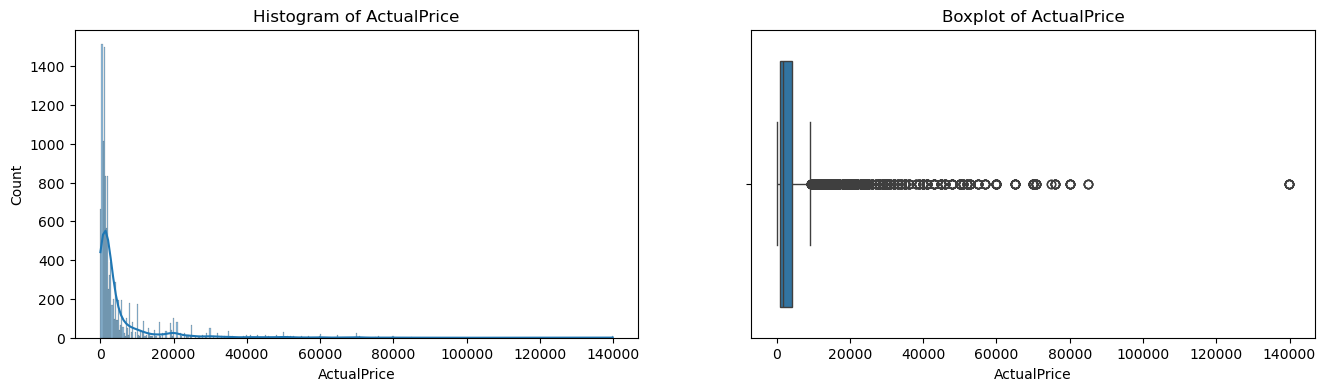

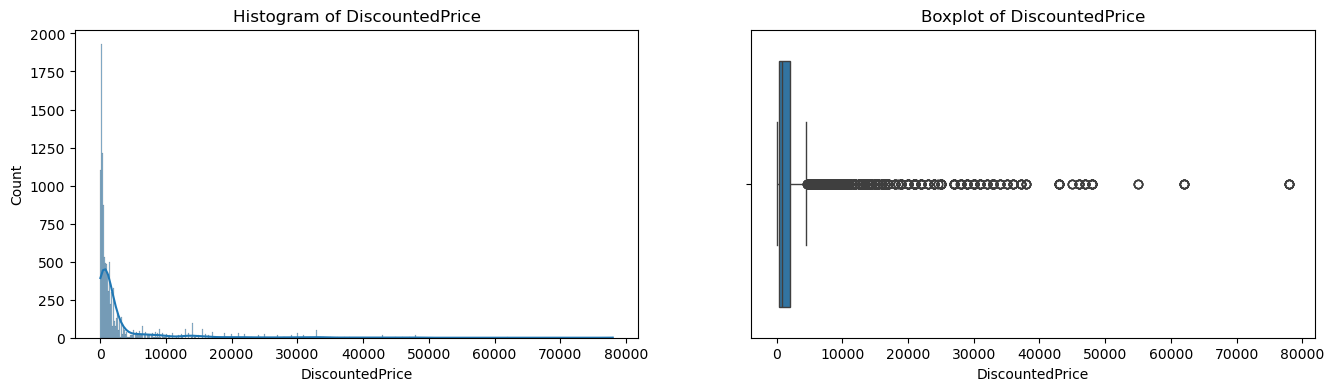

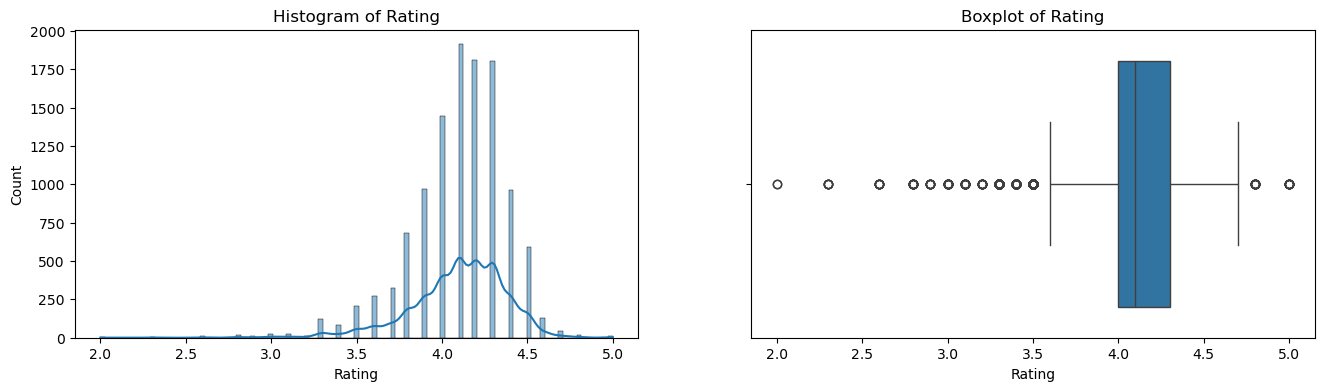

In [65]:
columns_to_check = ['ActualPrice', 'DiscountedPrice', 'Rating']

# Reset index to avoid issues with duplicate labels
df = df.reset_index(drop=True)

# Histograms and box plots to check outliers
for column in columns_to_check:
    plt.figure(figsize=(16, 4))

    # Plot histogram
    plt.subplot(1, 2, 1)
    sns.histplot(df[column], kde=True)
    plt.title(f'Histogram of {column}')
    
    # Plot box plot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot of {column}')
    
    plt.show()

**Feature Scaling**

**1. Min-Max Scaling**

In [69]:
#from sklearn.preprocessing import MinMaxScaler

# Define the features to scale
# features_to_scale = ['DiscountedPrice', 'ActualPrice', 'DiscountedPercentage', 'Rating', 'RatingCount']

# Initialize the MinMaxScaler
# scaler = MinMaxScaler()

# Apply scaling to the selected features
# df[features_to_scale] = scaler.fit_transform(df[features_to_scale])

# Display the scaled values to verify
#print(df[features_to_scale].head(10))

**EDA (Exploratory Data Analysis)**

**1. Unique values of DiscountedPrice, ActualPrice, Rating, DiscountedPercentage columns**

In [73]:
# Unique values of DiscountedPrice, ActualPrice, Rating, DiscountedPercentage columns
num_discounted_prices = df['DiscountedPrice'].nunique()
num_actual_prices = df['ActualPrice'].nunique()
num_ratings = df['Rating'].nunique()
num_discounted_percentages = df['DiscountedPercentage'].nunique()

print(f"Number of unique discounted prices: {num_discounted_prices}")
print(f"Number of unique actual prices: {num_actual_prices}")
print(f"Number of unique ratings: {num_ratings}")
print(f"Number of unique discount percentages: {num_discounted_percentages}")

Number of unique discounted prices: 550
Number of unique actual prices: 449
Number of unique ratings: 25
Number of unique discount percentages: 92


In [75]:
# Sort unique ratings in ascending order
unique_ratings = df['Rating'].unique()
unique_ratings_sorted = sorted(unique_ratings)

# Display unique ratings with extra spaces between them
unique_ratings_str = "    ".join(map(str, unique_ratings_sorted))
print(f"Unique Ratings: {unique_ratings_str}")

Unique Ratings: 2.0    2.3    2.6    2.8    2.9    3.0    3.1    3.2    3.3    3.4    3.5    3.6    3.7    3.8    3.9    4.0    4.1    4.2    4.3    4.4    4.5    4.6    4.7    4.8    5.0    nan


**2. Summary statistics for numerical columns**

In [78]:
# Summary statistics for numerical columns
df.describe()

,DiscountedPrice,ActualPrice,DiscountedPercentage,Rating,RatingCount
count,11503.000000,11503.000000,11503.000000,11495.000000,11503.000000
mean,3009.465656,5254.438950,47.733287,4.097816,78.785013
std,6694.994950,10443.428608,21.601398,0.281933,193.664950
min,39.000000,39.000000,0.000000,2.000000,0.000000
25%,320.000000,800.000000,32.000000,4.000000,0.000000
50%,799.000000,1630.000000,50.000000,4.100000,0.000000
75%,1999.000000,4200.000000,63.000000,4.300000,0.000000
max,77990.000000,139900.000000,94.000000,5.000000,992.000000


**3. Heatmap for correlations between numerical columns**

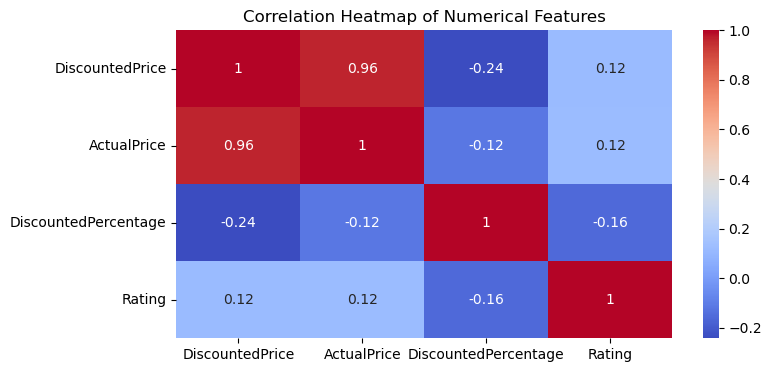

In [81]:
# heatmap for correlations between numerical columns
# Select numerical columns only
numerical_columns = df.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(8, 4))
sns.heatmap(numerical_columns.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [83]:
# CONCLUSIONS
# 1. DiscountedPrice, ActualPrice
# strong positive correlation (0.96) 
# products with higher actual prices also tend to have higher discounted prices

# 2. Rating and ActualPrice
# weak and positive correlation (0.12)
# a very minimal relationship between actual price and rating
# suggest that the price of the product does not significantly influence the ratings it receives

**4. Enhanced heatmap - clustering and grouping**

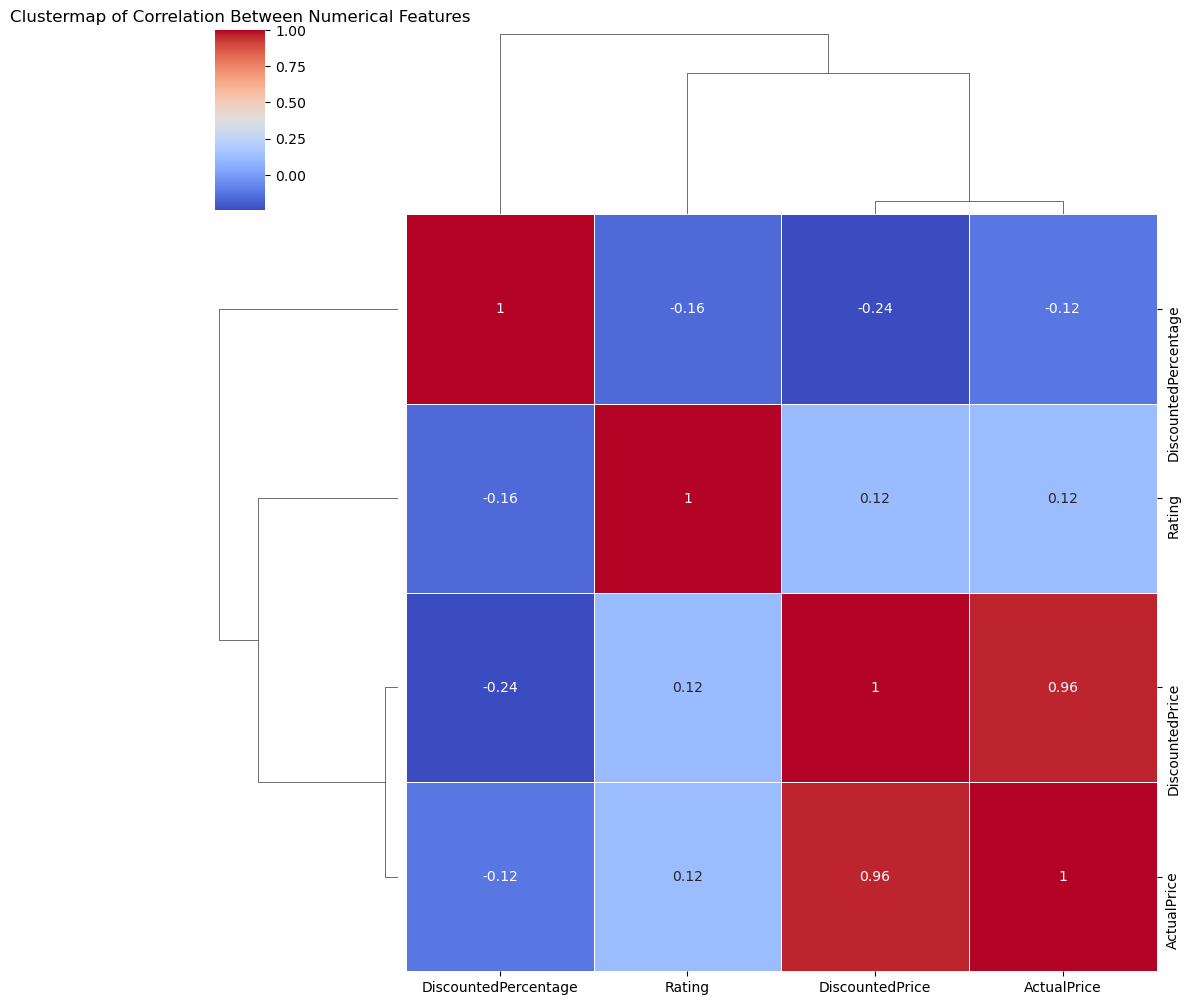

In [86]:
# enhanced heatmap analysis by applying clustering and grouping (using seaborn's clustermap function)
# Select numerical columns only
numerical_columns = df.select_dtypes(include=['float64', 'int64'])

# Compute correlation matrix
corr_matrix = numerical_columns.corr()

# Generate a clustermap
sns.clustermap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Clustermap of Correlation Between Numerical Features")
plt.show()

**5. User Interaction Distribution**

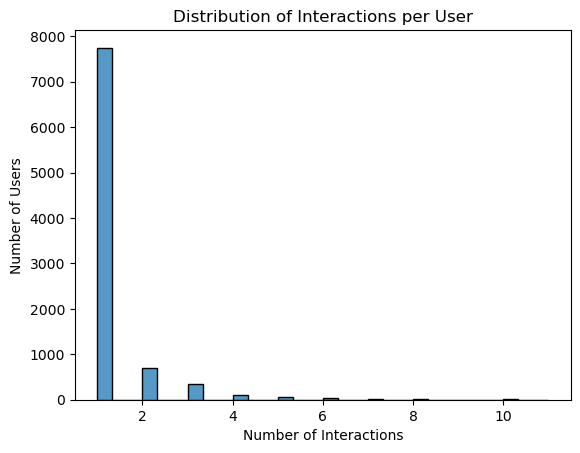

In [89]:
# Distribution of Interactions per User

# How many interactions (reviews/ratings) each user has made
interactions_per_user = df['UserID'].value_counts()

sns.histplot(interactions_per_user, kde=False, bins=30)
plt.xlabel('Number of Interactions')
plt.ylabel('Number of Users')
plt.title('Distribution of Interactions per User')
plt.show()

**6. Item Interaction Distribution**

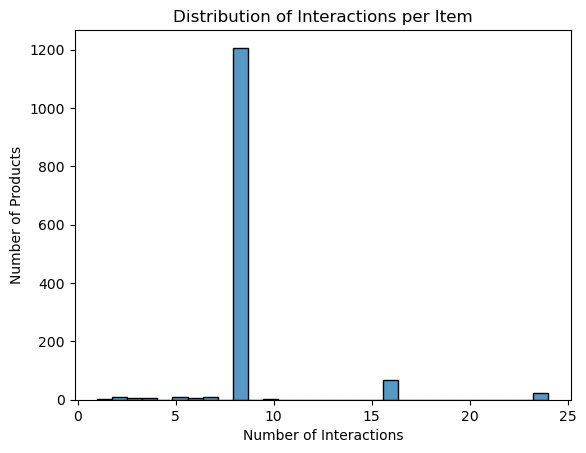

In [92]:
# Number of interactions each product has received

# How many interactions each product has
interactions_per_item = df['ProductID'].value_counts()

sns.histplot(interactions_per_item, kde=False, bins=30)
plt.xlabel('Number of Interactions')
plt.ylabel('Number of Products')
plt.title('Distribution of Interactions per Item')
plt.show()

**7. Top-rated products**

In [95]:
# average rating for each product
top_rated_products = df.groupby('ProductName')['Rating'].mean().sort_values(ascending=False)

# creates a new DataFrame from the grouped result, with a new index for each product
top_rated_products_df = top_rated_products.reset_index()

# renames the columns of the resulting DataFrame to something more meaningful
top_rated_products_df.columns = ['ProductName', 'AverageRating']

# removes any products where the AverageRating is NaN
top_rated_products_df = top_rated_products_df.dropna(subset=['AverageRating'])

top_rated_products_df

,ProductName,AverageRating
0,Amazon Basics Wireless Mouse | 2.4 GHz Connect...,5.0
1,Syncwire LTG to USB Cable for Fast Charging Co...,5.0
2,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",5.0
3,"Instant Pot Air Fryer, Vortex 2QT, Touch Contr...",4.8
4,Swiffer Instant Electric Water Heater Faucet T...,4.8
...,...,...
1331,SHREENOVA ID116 Plus Bluetooth Fitness Smart W...,2.8
1332,MR. BRAND Portable USB Juicer Electric USB Jui...,2.8
1333,Green Tales Heat Seal Mini Food Sealer-Impulse...,2.6
1334,"Personal Size Blender, Portable Blender, Batte...",2.3


**Most-reviewed products**

In [98]:
# calculates the total number of ratings for each product
most_rated_products = df.groupby('ProductName')['RatingCount'].sum().sort_values(ascending=False)

# resets the index to convert ProductName back to a regular column and create a new numeric index
most_rated_products_df = most_rated_products.reset_index()

# Renames the columns of the DataFrame to indicate that it contains the product names and their total ratings
most_rated_products_df.columns = ['ProductName', 'TotalRatings']

most_rated_products_df

,ProductName,TotalRatings
0,Duracell USB Lightning Apple Certified (Mfi) B...,19560
1,Zoul USB C 60W Fast Charging 3A 6ft/2M Long Ty...,15584
2,Ambrane 2 in 1 Type-C & Micro USB Cable with 6...,14448
3,Wecool Unbreakable 3 in 1 Charging Cable with ...,10496
4,"Sounce 65W OnePlus Dash Warp Charge Cable, 6.5...",9208
...,...,...
1332,MI 33W SonicCharge 2.0 USB Charger for Cellula...,0
1333,MI 360° Home Security Wireless Camera 2K Pro w...,0
1334,MI 80 cm (32 inches) 5A Series HD Ready Smart ...,0
1335,MI 80 cm (32 inches) HD Ready Smart Android LE...,0


**8. Distribution of product ratings**

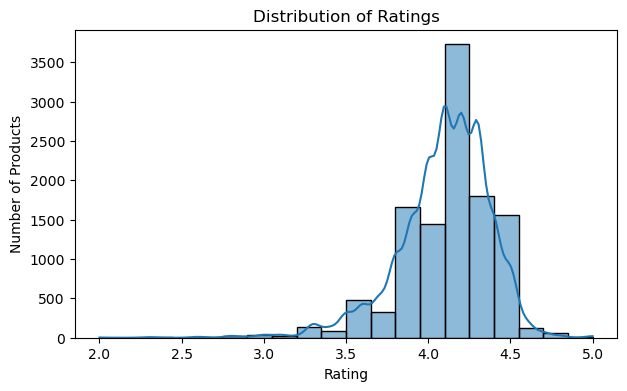

In [101]:
# Visualizing Distribution of product ratings 
# helps to understand the sentiment of the reviews
# helps to see whether most products are rated highly or if there’s a broad spread of ratings
plt.figure(figsize=(7, 4))
sns.histplot(df['Rating'], bins=20, kde=True)
plt.xlabel('Rating')
plt.ylabel('Number of Products')
plt.title('Distribution of Ratings')
plt.show()

# CONCLUSION : the platform has a high level of customer satisfaction (most products have ratings between 4.0 and 4.5)

**9. Correlation Between Price and Ratings**

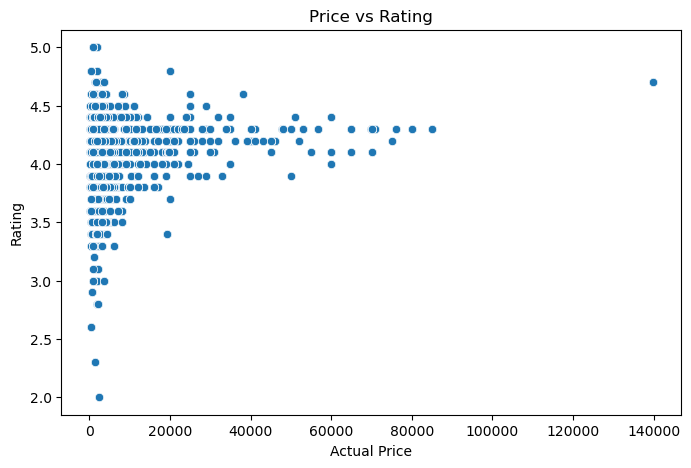

In [104]:
# Correlation Between Price and Ratings

# can explore if there’s any relationship between product prices and their ratings
# This might indicate whether higher-priced items tend to have better review
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['ActualPrice'], y=df['Rating'])
plt.xlabel('Actual Price')
plt.ylabel('Rating')
plt.title('Price vs Rating')
plt.show()

# CONCLUSION : price may not be a strong predictor of product rating

**10. Top Products with the highest discounts**

In [107]:
# Top Products with the highest discounts
top_discounted_products = df[['ProductName', 'DiscountedPercentage']].sort_values(by='DiscountedPercentage', ascending=False).head(15)
top_discounted_products

,ProductName,DiscountedPercentage
5444,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94
5443,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94
5442,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94
5441,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94
5440,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94
5439,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94
5438,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94
5437,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",94
2876,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91
2848,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",91


**11. Most frequent categories**

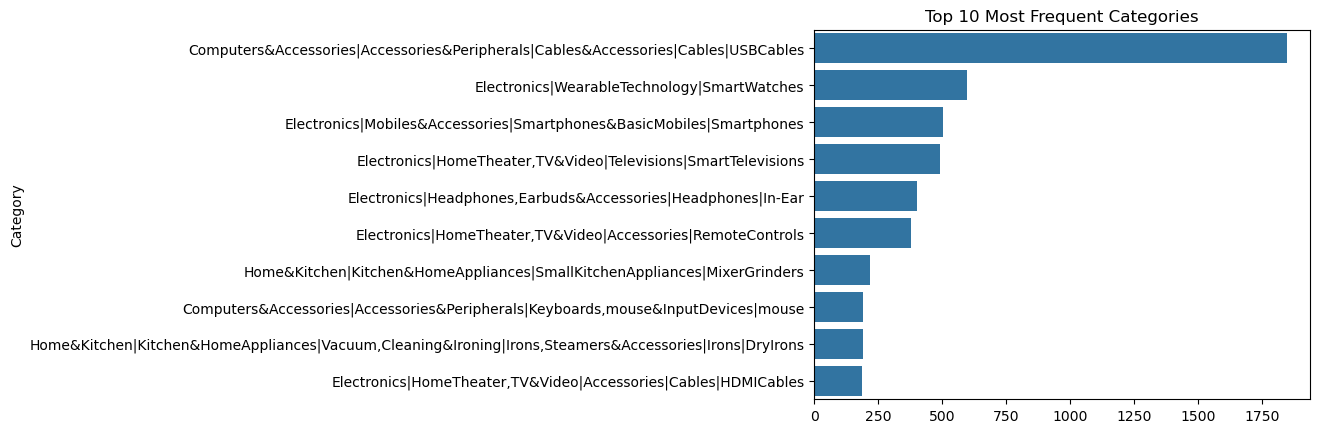

In [110]:
# Most frequent categories
category_counts = df['Category'].value_counts().head(10)
sns.barplot(y=category_counts.index, x=category_counts.values)
plt.title('Top 10 Most Frequent Categories')
plt.show()

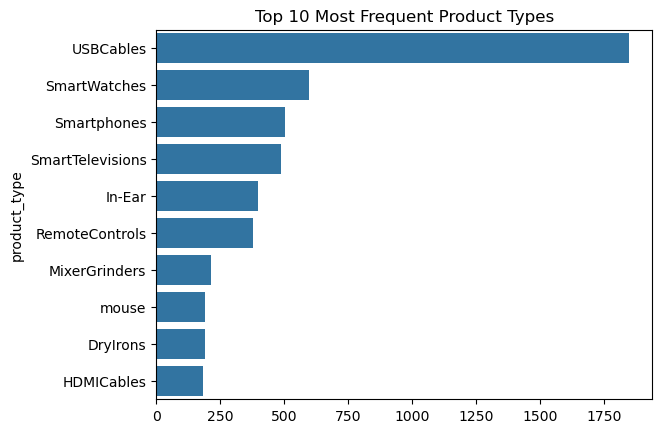

In [112]:
# Most frequent product types
product_type_counts = df['product_type'].value_counts().head(10)
sns.barplot(y=product_type_counts.index, x=product_type_counts.values)
plt.title('Top 10 Most Frequent Product Types')
plt.show()

**Categories with highest average ratings**

In [115]:
# Categories with highest average ratings
category_avg_rating = df.groupby('Category')['Rating'].mean().sort_values(ascending=False).head(10)
print(category_avg_rating)

Category
Computers&Accessories|Tablets                                                                 4.6
Computers&Accessories|NetworkingDevices|NetworkAdapters|PowerLANAdapters                      4.5
Electronics|PowerAccessories|SurgeProtectors                                                  4.5
Computers&Accessories|Components|Memory                                                       4.5
Electronics|Cameras&Photography|Accessories|Film                                              4.5
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|SmallApplianceParts&Accessories    4.5
Home&Kitchen|Kitchen&HomeAppliances|Coffee,Tea&Espresso|CoffeePresses                         4.5
HomeImprovement|Electrical|CordManagement                                                     4.5
Electronics|HomeAudio|MediaStreamingDevices|StreamingClients                                  4.5
OfficeProducts|OfficeElectronics|Calculators|Basic                                            4.5
Name: Ratin

**Product Types with highest average ratings**

In [118]:
# product types with highest average ratings
product_type_avg_rating = df.groupby('product_type')['Rating'].mean().sort_values(ascending=False).head(10)
print(product_type_avg_rating)

product_type
Tablets                            4.6
SurgeProtectors                    4.5
Basic                              4.5
Memory                             4.5
SmallApplianceParts&Accessories    4.5
CordManagement                     4.5
CoffeePresses                      4.5
StreamingClients                   4.5
PowerLANAdapters                   4.5
PaintingMaterials                  4.5
Name: Rating, dtype: float64


**12. Top Users by Activity**

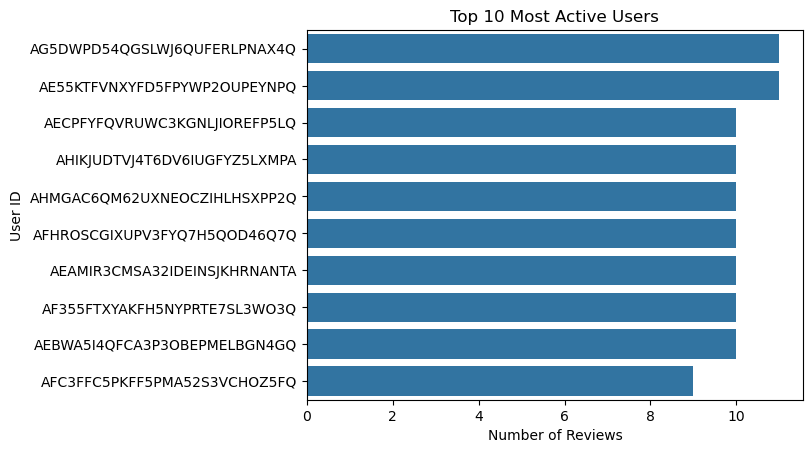

In [121]:
# Top Users by Activity (in terms of the number of reviews or ratings they have left)
top_users = df['UserID'].value_counts().head(10)
sns.barplot(x=top_users.values, y=top_users.index)
plt.xlabel('Number of Reviews')
plt.ylabel('User ID')
plt.title('Top 10 Most Active Users')
plt.show()

# userIDs are too long:
# - Truncate User IDs for Display
# - user1, user2,...

**13. Sentiment Distribution of Reviews**

In [124]:
!pip install nltk

In [125]:
import nltk
nltk.download('brown')
nltk.download('punkt')

[nltk_data] Downloading package brown to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [128]:
pip install textblob

Note: you may need to restart the kernel to use updated packages.


In [129]:
df.head(10)

,ProductID,ProductName,Category,DiscountedPrice,ActualPrice,DiscountedPercentage,Rating,RatingCount,AboutProduct,UserID,UserName,ReviewID,ReviewTitle,Review,ImageLink,ProductLink,product_type
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,R3HXWT0LRP0NMF,Satisfied,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
1,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta,R2AJM3LFTLZHFO,Charging is really fast,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
2,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AHCTC6ULH4XB6YHDY6PCH2R772LQ,Sundeep,R6AQJGUP6P86,Value for money,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
3,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AGYHHIERNXKA6P5T7CZLXKVPT7IQ,S.Sayeed Ahmed,R1KD19VHEDV0OR,Product review,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
4,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AG4OGOFWXJZTQ2HKYIOCOY3KXF2Q,jaspreet singh,R3C02RMYQMK6FC,Good quality,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
5,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AENGU523SXMOS7JPDTW52PNNVWGQ,Khaja moin,R39GQRVBUZBWGY,Good product,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
6,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AEQJHCVTNINBS4FKTBGQRQTGTE5Q,Anand,R2K9EDOE15QIRJ,Good Product,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
7,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AFC3FFC5PKFF5PMA52S3VCHOZ5FQ,S.ARUMUGAM,R3OI7YT648TL8I,As of now seems good,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables
8,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43,4.0,0,"Compatible with all Type C enabled devices, be...",AECPFYFQVRUWC3KGNLJIOREFP5LQ,ArdKn,RGIQEG07R9HS2,A Good Braided Cable for Your Type C Device,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,USBCables
9,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43,4.0,0,"Compatible with all Type C enabled devices, be...",AGYYVPDD7YG7FYNBXNGXZJT525AQ,Nirbhay kumar,R1SMWZQ86XIN8U,Good quality product from ambrane,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-U

In [130]:
from textblob import TextBlob

# Function to categorize polarity into sentiment labels
def get_sentiment_label(review):
    polarity = TextBlob(review).sentiment.polarity
    if polarity > 0:
        return 'Positive'
    elif polarity < 0:
        return 'Negative'
    else:
        return 'Neutral'

# Apply sentiment analysis directly to create the 'SentimentLabel' column
df['ReviewSentiment'] = df['Review'].apply(get_sentiment_label)

df.head(1)

,ProductID,ProductName,Category,DiscountedPrice,ActualPrice,DiscountedPercentage,Rating,RatingCount,AboutProduct,UserID,UserName,ReviewID,ReviewTitle,Review,ImageLink,ProductLink,product_type,ReviewSentiment
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,R3HXWT0LRP0NMF,Satisfied,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables,Negative


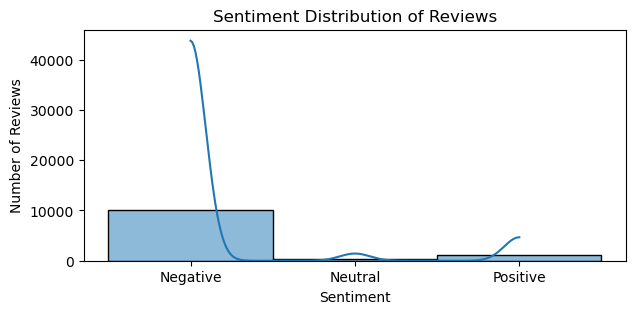

In [133]:
# Visualize the sentiment scores
plt.figure(figsize=(7, 3))
sns.histplot(df['ReviewSentiment'], bins=20, kde=True)
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.title('Sentiment Distribution of Reviews')
plt.show()

# -1 ---> very negative
# 0 ---> neutral
# 1 ---> very positive 
# CONCLUSION :  the platform offers a decent shopping experience, but there's room to increase customer enthusiasm

**Tag Creation**

In [137]:
!pip install spacy

In [139]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     --------------------------------------- 0.1/12.8 MB 409.6 kB/s eta 0:00:32
     --------------------------------------- 0.1/12.8 MB 476.3 kB/s eta 0:00:27
     --------------------------------------- 0.1/12.8 MB 554.9 kB/s eta 0:00:23
      -------------------------------------- 0.2/12.8 MB 655.4 kB/s eta 0:00:20
      -------------------------------------- 0.2/12.8 MB 765.3 kB/s eta 0:00:17
     - -------------------------------------- 0.4/12.8 MB 1.2 MB/s eta 0:00:11
     - -------------------------------------- 0.5/12.8 MB 1.3 MB/s eta 0:00:10
     - -------------------------------------- 0.6/12.8 MB 1.4 MB/s eta 0:00:09
     -- ------------------------------------- 0.7/12.8 MB 1.5 MB/s eta 0:00:09
     -- ------------------------------------- 0.8/12.8 MB 1.6 MB/s e

In [140]:
import spacy
from spacy.lang.en.stop_words import STOP_WORDS

# Load the spaCy language model
nlp = spacy.load("en_core_web_sm")

In [141]:
df.head(2)

,ProductID,ProductName,Category,DiscountedPrice,ActualPrice,DiscountedPercentage,Rating,RatingCount,AboutProduct,UserID,UserName,ReviewID,ReviewTitle,Review,ImageLink,ProductLink,product_type,ReviewSentiment
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,R3HXWT0LRP0NMF,Satisfied,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables,Negative
1,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,0,High Compatibility : Compatible With iPhone 12...,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta,R2AJM3LFTLZHFO,Charging is really fast,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables,Negative


In [145]:
# Merge original columns back into the cleaned DataFrame
df['OriginalProductName'] = df['ProductName']
df['OriginalCategory'] = df['Category']
df['OriginalAboutProduct'] = df['AboutProduct']

In [147]:
# Function to clean text and extract tags
def clean_and_extract_tags(text):
    # Process the text with spaCy
    doc = nlp(text.lower())
    
    # Extract alphanumeric tokens that are not stop words
    tags = [token.text for token in doc if token.text.isalnum() and token.text not in STOP_WORDS]
    
    # Join the tags with commas
    return ', '.join(tags)

In [149]:
# Function to clean and extract tags for the Category column
def clean_and_extract_category_tags(text):
    # Split the text on | and & and convert to lowercase
    tags = text.replace('|', ' ').replace('&', ' ').lower().split()
    return ', '.join(tags)

In [151]:
# Apply the cleaning and tag extraction function to each relevant column
df['ProductName'] = df['ProductName'].apply(clean_and_extract_tags)
df['Category'] = df['Category'].apply(clean_and_extract_category_tags)
df['AboutProduct'] = df['AboutProduct'].apply(clean_and_extract_tags)

In [152]:
# Concatenate the cleaned tags from all relevant columns into a new 'Tags' column
df['Tags'] = df[['ProductName', 'Category', 'AboutProduct']].apply(lambda row: ', '.join(row), axis=1)

In [153]:
# Define the columns from which to extract tags
columns_to_extract_tags_from = ['ProductName', 'Category', 'AboutProduct']

In [154]:
# Display the dataframe with the new 'Tags' column
df[['ProductName', 'Category', 'AboutProduct', 'Tags']].head()

,ProductName,Category,AboutProduct,Tags
0,"wayona, nylon, braided, usb, lightning, fast, ...","computers, accessories, accessories, periphera...","high, compatibility, compatible, iphone, 12, 1...","wayona, nylon, braided, usb, lightning, fast, ..."
1,"wayona, nylon, braided, usb, lightning, fast, ...","computers, accessories, accessories, periphera...","high, compatibility, compatible, iphone, 12, 1...","wayona, nylon, braided, usb, lightning, fast, ..."
2,"wayona, nylon, braided, usb, lightning, fast, ...","computers, accessories, accessories, periphera...","high, compatibility, compatible, iphone, 12, 1...","wayona, nylon, braided, usb, lightning, fast, ..."
3,"wayona, nylon, braided, usb, lightning, fast, ...","computers, accessories, accessories, periphera...","high, compatibility, compatible, iphone, 12, 1...","wayona, nylon, braided, usb, lightning, fast, ..."
4,"wayona, nylon, braided, usb, lightning, fast, ...","computers, accessories, accessories, periphera...","high, compatibility, compatible, iphone, 12, 1...","wayona, nylon, braided, usb, lightning, fast, ..."


**14. Most frequent categories (after creating tags)**

In [156]:
from collections import Counter
 
# Split the 'Category' column tags into individual tags
category_tags = df['Category'].apply(lambda x: x.split(','))

# Flatten the list of tags and remove extra spaces
all_tags = [tag.strip() for sublist in category_tags for tag in sublist]

# Get the unique tags using a set 
unique_tags = set(all_tags)

# Display the unique tags
print("Unique Category Tags:")
for tag in unique_tags:
    print(tag)

Unique Category Tags:
disposablebatteries
bluetoothadapters
smartphones
extenders
mediastreamingdevices
measuringspoons
kitchen
markers
health
macro
generalpurposebatteries
turntables
inductioncooktop
cartridges
purifiers
notepads
cables
externalharddisks
airfryers
wet-dryvacuums
selfiesticks
waterpurifiers
rechargeablebatteries
earpads
tape
diaries
paper
airpurifiers
ceilingmounts
wetgrinders
electronics
watercartridges
smallkitchenappliances
standmixeraccessories
laundryorganization
batterychargers
videocameras
mills
eggboilers
standardtelevisions
pedestalfans
stationery
motorbike
video
toastersets
photobackgroundaccessories
airconditioners
arts
electrickettles
humidifiers
games
dining
homeimprovement
traveltripods
inkjetprinters
outdoorspeakers
homeappliances
slipcases
deepfatfryers
woodenpencils
drawingmedia
harddiskbags
electrical
ionizers
tonercartridges
harddriveaccessories
handmixers
officeproducts
vacuumbags
paintingmaterials
poweraccessories
juicermixergrinders
tablefans
coff

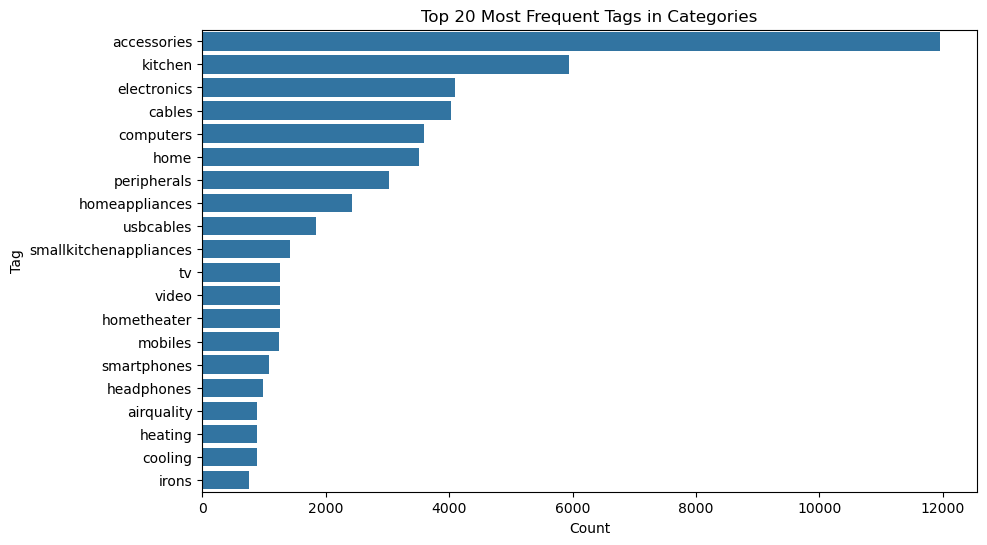

In [162]:
# Count the frequency of each unique tag
tag_counts = Counter(all_tags)

# Convert the tag counts to a DataFrame for plotting
tag_counts_df = pd.DataFrame(tag_counts.items(), columns=['Tag', 'Count']).sort_values(by='Count', ascending=False)

# Plot the top 20 most frequent tags
plt.figure(figsize=(10, 6))
sns.barplot(x='Count', y='Tag', data=tag_counts_df.head(20))
plt.title('Top 20 Most Frequent Tags in Categories')
plt.xlabel('Count')
plt.ylabel('Tag')
plt.show()

In [163]:
# Save DataFrame to CSV
df.to_csv('data_after_preprocessing.csv', index=False)

In [165]:
df_original = df.copy()

In [166]:
df_preprocessed = df.copy()

**Rating Based Recommendation**

In [171]:
df_preprocessed.columns

Index(['ProductID', 'ProductName', 'Category', 'DiscountedPrice',
       'ActualPrice', 'DiscountedPercentage', 'Rating', 'RatingCount',
       'AboutProduct', 'UserID', 'UserName', 'ReviewID', 'ReviewTitle',
       'Review', 'ImageLink', 'ProductLink', 'product_type', 'ReviewSentiment',
       'OriginalProductName', 'OriginalCategory', 'OriginalAboutProduct',
       'Tags'],
      dtype='object')

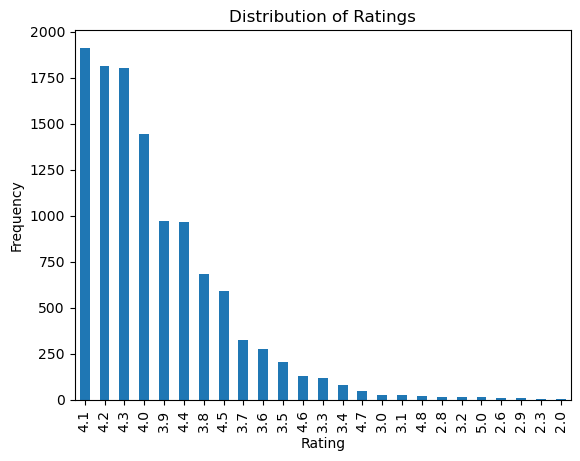

In [173]:
# Plot the value counts of the Rating column as a bar chart
df_preprocessed['Rating'].value_counts().plot(kind='bar')

plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')

plt.show()

In [175]:
# Group by 'ProductName', 'RatingCount', 'Category', 'ImageLink' to calculate the average rating for each product
average_ratings = df_preprocessed.groupby(['ProductName', 'RatingCount', 'Category', 'ImageLink'])['Rating'].mean().reset_index()

# Sort products by average rating in descending order
top_rated_items = average_ratings.sort_values(by='Rating', ascending=False)

# Select the top 10 highest-rated products
rating_base_recommendation = top_rated_items.head(10)

# Convert 'Rating' and 'RatingCount' columns to integer for better presentation
rating_base_recommendation.loc[:, 'Rating'] = rating_base_recommendation['Rating'].astype(int)
rating_base_recommendation.loc[:, 'RatingCount'] = rating_base_recommendation['RatingCount'].astype(int)

# Display the results of the rating-based recommendation system
rating_base_recommendation.loc[:, ['ProductName', 'Rating', 'RatingCount', 'Category', 'ImageLink']] = rating_base_recommendation[['ProductName', 'Rating', 'RatingCount', 'Category', 'ImageLink']]

# Show the top 10 recommended products
rating_base_recommendation

,ProductName,RatingCount,Category,ImageLink,Rating
1228,"syncwire, ltg, usb, cable, fast, charging, com...",5,"computers, accessories, accessories, periphera...",https://m.media-amazon.com/images/I/317OoQfs1g...,5.0
1077,"redtech, usb, c, lightning, cable, ft, apple, ...",0,"computers, accessories, accessories, periphera...",https://m.media-amazon.com/images/I/31-q0xhaTA...,5.0
81,"amazon, basics, wireless, mouse, ghz, connecti...",23,"computers, accessories, accessories, periphera...",https://m.media-amazon.com/images/I/31+Rg6Z46d...,5.0
1226,"swiffer, instant, electric, water, heater, fau...",0,"home, kitchen, heating,cooling, airquality, wa...",https://m.media-amazon.com/images/I/41+t2HWvwF...,4.0
890,"oratech, coffee, frother, electric, milk, frot...",28,"home, kitchen, kitchen, homeappliances, smallk...",https://m.media-amazon.com/images/W/WEBP_40237...,4.0
618,"instant, pot, air, fryer, vortex, 2qt, touch, ...",0,"home, kitchen, kitchen, homeappliances, smallk...",https://m.media-amazon.com/images/W/WEBP_40237...,4.0
1191,"spigen, ez, fit, tempered, glass, screen, prot...",0,"electronics, mobiles, accessories, mobileacces...",https://m.media-amazon.com/images/I/51EiPNlJDg...,4.0
826,"multifunctional, 2, 1, electric, egg, boiling,...",0,"home, kitchen, kitchen, homeappliances, smallk...",https://m.media-amazon.com/images/W/WEBP_40237...,4.0
1431,"zuvexa, usb, rechargeable, electric, foam, mak...",54,"home, kitchen, kitchen, homeappliances, smallk...",https://m.media-amazon.com/images/I/41714O1hnm...,4.0
457,"figment, handheld, milk, frother, rechargeable...",0,"home, kitchen, kitchen, homeappliances, smallk...",https://m.media-amazon.com/images/I/51oN+8Zs5Y...,4.0


In [177]:
df.head(1)

,ProductID,ProductName,Category,DiscountedPrice,ActualPrice,DiscountedPercentage,Rating,RatingCount,AboutProduct,UserID,...,ReviewTitle,Review,ImageLink,ProductLink,product_type,ReviewSentiment,OriginalProductName,OriginalCategory,OriginalAboutProduct,Tags
0,B07JW9H4J1,"wayona, nylon, braided, usb, lightning, fast, ...","computers, accessories, accessories, periphera...",399.0,1099.0,64,4.2,0,"high, compatibility, compatible, iphone, 12, 1...",AG3D6O4STAQKAY2UVGEUV46KN35Q,...,Satisfied,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables,Negative,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,High Compatibility : Compatible With iPhone 12...,"wayona, nylon, braided, usb, lightning, fast, ..."


**Displaying the top rated products**

In [180]:
def get_top_rated_products(df, top_n=10):
 
    # Group by 'ProductName', 'RatingCount', 'ImageLink' to calculate the average rating
    average_ratings = df.groupby(['ProductName', 'RatingCount', 'ImageLink'])['Rating'].mean().reset_index()

    # Sort products by average rating in descending order
    top_rated_items = average_ratings.sort_values(by='Rating', ascending=False)

    # Select the top N highest-rated products
    rating_based_recommendation = top_rated_items.head(top_n)

    # Convert 'Rating' and 'RatingCount' columns to integer for cleaner presentation
    rating_based_recommendation.loc[:, 'Rating'] = rating_based_recommendation['Rating'].astype(int)
    rating_based_recommendation.loc[:, 'RatingCount'] = rating_based_recommendation['RatingCount'].astype(int)

    # Return the top-rated products
    return rating_based_recommendation[['ProductName', 'Rating', 'RatingCount', 'ImageLink']]

# Example usage: Get top 10 rated products across all categories
top_rated_products = get_top_rated_products(df_preprocessed, top_n=10)

# Display the result
top_rated_products

,ProductName,Rating,RatingCount,ImageLink
1228,"syncwire, ltg, usb, cable, fast, charging, com...",5.0,5,https://m.media-amazon.com/images/I/317OoQfs1g...
1077,"redtech, usb, c, lightning, cable, ft, apple, ...",5.0,0,https://m.media-amazon.com/images/I/31-q0xhaTA...
81,"amazon, basics, wireless, mouse, ghz, connecti...",5.0,23,https://m.media-amazon.com/images/I/31+Rg6Z46d...
1226,"swiffer, instant, electric, water, heater, fau...",4.0,0,https://m.media-amazon.com/images/I/41+t2HWvwF...
890,"oratech, coffee, frother, electric, milk, frot...",4.0,28,https://m.media-amazon.com/images/W/WEBP_40237...
618,"instant, pot, air, fryer, vortex, 2qt, touch, ...",4.0,0,https://m.media-amazon.com/images/W/WEBP_40237...
1191,"spigen, ez, fit, tempered, glass, screen, prot...",4.0,0,https://m.media-amazon.com/images/I/51EiPNlJDg...
826,"multifunctional, 2, 1, electric, egg, boiling,...",4.0,0,https://m.media-amazon.com/images/W/WEBP_40237...
1431,"zuvexa, usb, rechargeable, electric, foam, mak...",4.0,54,https://m.media-amazon.com/images/I/41714O1hnm...
457,"figment, handheld, milk, frother, rechargeable...",4.0,0,https://m.media-amazon.com/images/I/51oN+8Zs5Y...


**Displaying the top rated products by category**

In [183]:
# Function to filter by category and recommend top-rated products
def get_top_rated_by_category(df_preprocessed, category, top_n=10):
    # Filter the data by the given category
    filtered_data = df_preprocessed[df_preprocessed['Category'].str.contains(category, case=False, na=False)]

    # Group by 'ProductName', 'RatingCount', 'Category', 'ImageLink' to calculate the average rating
    average_ratings = filtered_data.groupby(['ProductName', 'RatingCount', 'Category', 'ImageLink'])['Rating'].mean().reset_index()

    # Sort products by average rating in descending order
    top_rated_items = average_ratings.sort_values(by='Rating', ascending=False)

    # Select the top N highest-rated products (default is top 10)
    rating_base_recommendation = top_rated_items.head(top_n)

    # Convert 'Rating' and 'RatingCount' columns to integers for cleaner presentation
    rating_base_recommendation.loc[:, 'Rating'] = rating_base_recommendation['Rating'].astype(int)
    rating_base_recommendation.loc[:, 'RatingCount'] = rating_base_recommendation['RatingCount'].astype(int)

    print(f"Rating-Based Recommendation System for Category: {category} (Trending Products)")
    return rating_base_recommendation[['ProductName', 'Rating', 'RatingCount', 'Category', 'ImageLink']]

In [185]:
# Example usage: Get top 10 rated products in "accessories"
category = "accessories"  
top_rated_by_category = get_top_rated_by_category(df_preprocessed, category, top_n=10)

top_rated_by_category

Rating-Based Recommendation System for Category: accessories (Trending Products)


,ProductName,Rating,RatingCount,Category,ImageLink
44,"amazon, basics, wireless, mouse, ghz, connecti...",5.0,23,"computers, accessories, accessories, periphera...",https://m.media-amazon.com/images/I/31+Rg6Z46d...
598,"redtech, usb, c, lightning, cable, ft, apple, ...",5.0,0,"computers, accessories, accessories, periphera...",https://m.media-amazon.com/images/I/31-q0xhaTA...
711,"syncwire, ltg, usb, cable, fast, charging, com...",5.0,5,"computers, accessories, accessories, periphera...",https://m.media-amazon.com/images/I/317OoQfs1g...
683,"spigen, ez, fit, tempered, glass, screen, prot...",4.0,0,"electronics, mobiles, accessories, mobileacces...",https://m.media-amazon.com/images/I/51EiPNlJDg...
0,"10k, 8k, 4k, hdmi, cable, certified, 48gbps, 1...",4.0,0,"electronics, hometheater,tv, video, accessorie...",https://m.media-amazon.com/images/W/WEBP_40237...
407,"lint, remover, woolen, clothes, lint, extracto...",4.0,124,"home, kitchen, kitchen, homeappliances, vacuum...",https://m.media-amazon.com/images/W/WEBP_40237...
682,"spigen, ez, fit, tempered, glass, screen, prot...",4.0,0,"electronics, mobiles, accessories, mobileacces...",https://m.media-amazon.com/images/I/51R2kfyMW5...
681,"spigen, ez, fit, tempered, glass, screen, prot...",4.0,0,"electronics, mobiles, accessories, mobileacces...",https://m.media-amazon.com/images/I/41Usew0lrW...
113,"aquadpure, copper, mineral, 10, 12, liter, ro,...",4.0,124,"home, kitchen, kitchen, homeappliances, waterp...",https://m.media-amazon.com/images/W/WEBP_40237...
573,"redgear, mp35, speed, type, gaming, mousepad, ...",4.0,0,"computers, accessories, accessories, periphera...",https://m.media-amazon.com/images/W/WEBP_40237...


**Added the column seasonality**

In [188]:
# Tagging seasonality for certain products
df_preprocessed['Seasonality'] = df_preprocessed['ProductName'].apply(lambda x: 'Summer' if 'AC' in x or 'fan' in x else 'Winter' if 'heater' in x else 'All Seasons')
df_preprocessed.head(2)

,ProductID,ProductName,Category,DiscountedPrice,ActualPrice,DiscountedPercentage,Rating,RatingCount,AboutProduct,UserID,...,Review,ImageLink,ProductLink,product_type,ReviewSentiment,OriginalProductName,OriginalCategory,OriginalAboutProduct,Tags,Seasonality
0,B07JW9H4J1,"wayona, nylon, braided, usb, lightning, fast, ...","computers, accessories, accessories, periphera...",399.0,1099.0,64,4.2,0,"high, compatibility, compatible, iphone, 12, 1...",AG3D6O4STAQKAY2UVGEUV46KN35Q,...,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables,Negative,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,High Compatibility : Compatible With iPhone 12...,"wayona, nylon, braided, usb, lightning, fast, ...",All Seasons
1,B07JW9H4J1,"wayona, nylon, braided, usb, lightning, fast, ...","computers, accessories, accessories, periphera...",399.0,1099.0,64,4.2,0,"high, compatibility, compatible, iphone, 12, 1...",AHMY5CWJMMK5BJRBBSNLYT3ONILA,...,Not available,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,USBCables,Negative,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,High Compatibility : Compatible With iPhone 12...,"wayona, nylon, braided, usb, lightning, fast, ...",All Seasons


**KAVINDU**

**Content Base Recommendation system (User Preferences or Items similarities)**

In [192]:
pip install "fuzzywuzzy[speedup]"

Note: you may need to restart the kernel to use updated packages.


In [193]:
#pip install fuzzywuzzy\[speedup\]

In [194]:
pip install python-Levenshtein

Note: you may need to restart the kernel to use updated packages.


In [198]:
# Required libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from fuzzywuzzy import process  # Fuzzy matching library
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split

In [200]:
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

**Initialize the lemmatizer**

In [203]:
# Initialize the lemmatizer
lemmatizer = WordNetLemmatizer()

#The lemmatizer  is used to normalize the text data by reducing words to their base or root form.
#This process, called lemmatization, improves the accuracy of text analysis in your
#recommendation system by handling different forms of the same word in a consistent way.

**Lemmatize the text**

In [206]:
# Lemmatize the text
def preprocess(text):
    tokens = word_tokenize(text.lower())
    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in tokens]
    return ' '.join(lemmatized_tokens)

**Preprocess and combine relevant text features into a single column for vectorization**

In [209]:
# Preprocess and combine relevant text features into a single column for vectorization
# Combine relevant textual features into a single column for vectorization
# This helps capture all the descriptive attributes of a product (ProductName, Category, product_type, AboutProduct)
# into one string. By combining them, you can represent a product more comprehensively for recommendation purposes.
df['combined_features'] = df['ProductName'] + ' ' + df['Category'] + ' ' + df['product_type'] + ' ' + df['AboutProduct']

# Apply the 'preprocess' function (lemmatization, tokenization, lowercase) to the combined text features
# This ensures that the combined text is normalized (lowercased, tokenized, and lemmatized), improving comparison between products.
df['combined_features'] = df['combined_features'].apply(preprocess)


# Convert the 'product_type' column to lowercase
# This ensures that comparisons between product types are case-insensitive (e.g., "Electronics" and "electronics" are treated the same).
# Convert the product_type column to lowercase for consistent comparison
df['product_type'] = df['product_type'].str.lower()

**Function To Recommend Products for Content Base**

In [212]:
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.metrics.pairwise import cosine_similarity
# from fuzzywuzzy import process  # Assuming you're using this for fuzzy matching

# def content_based_recommendations(df, product_query, top_n=10):
#     """
#     Generate content-based recommendations by first filtering based on product type,
#     then ranking within that product type based on content similarity.
    
#     Parameters:
#     df (pd.DataFrame): The dataframe containing product information.
#     product_query (str): The product name or type to filter by (e.g., "Nokia" or "Smartphones").
#     top_n (int): Number of recommendations to return.
    
#     Returns:
#     pd.DataFrame: A dataframe containing the recommended products and their details, along with similarity scores.
#     """
#     # Normalize the user input for product query to lowercase
#     product_query = product_query.lower().strip()

#     # Step 1: Fuzzy matching based on product_type
#     all_product_types = df['product_type'].unique()  # Get all unique product types
#     best_match, match_score = process.extractOne(product_query, all_product_types)

#     # Check if the match score is sufficiently high for the product_type
#     if match_score < 60:  # You can adjust this threshold
#         print(f"No close match found for product type '{product_query}'. Closest match: '{best_match}' with score {match_score}")
#         return pd.DataFrame()

#     # Step 2: Filter the dataframe by the matched product_type
#     df_filtered = df[df['product_type'] == best_match]

#     if df_filtered.empty:
#         print(f"No products found for product type '{best_match}'.")
#         return pd.DataFrame()

#     # Step 3: Use TF-IDF on combined_features to rank products within the filtered product_type
#     tfidf_vectorizer = TfidfVectorizer(stop_words='english')
#     tfidf_matrix_filtered = tfidf_vectorizer.fit_transform(df_filtered['combined_features'])

#     # Compute Cosine Similarity matrix for the filtered products
#     cosine_similarities_filtered = cosine_similarity(tfidf_matrix_filtered)

#     # Get the top N most similar products for the first product in the filtered set
#     similar_items = list(enumerate(cosine_similarities_filtered[0]))
#     similar_items = sorted(similar_items[1:], key=lambda x: x[1], reverse=True)

#     # Get the indices of the recommended products
#     recommended_item_indices = [i[0] for i in similar_items]

#     # Extract the recommended products
#     recommended_products = df_filtered.iloc[recommended_item_indices]

#     # Drop duplicates based on 'ProductID' to ensure unique recommendations
#     unique_recommended_products = recommended_products.drop_duplicates(subset=['ProductID'])

#     # If there are fewer than top_n recommendations, append more random products to reach top_n
#     if unique_recommended_products.shape[0] < top_n:
#         additional_products = df_filtered.drop(unique_recommended_products.index).drop_duplicates(subset=['ProductID'])
#         additional_recommendations = additional_products.sample(n=min(top_n - unique_recommended_products.shape[0], additional_products.shape[0]))
#         unique_recommended_products = pd.concat([unique_recommended_products, additional_recommendations])

#     # Add similarity scores using .loc to avoid SettingWithCopyWarning
#     similarity_scores = [similar_items[i][1] for i in range(len(recommended_item_indices))]
#     unique_recommended_products.loc[:, 'Similarity_Score'] = similarity_scores[:len(unique_recommended_products)]

#     # Return the top_n unique recommended products along with their similarity scores
#     return unique_recommended_products.head(top_n)[['ProductName', 'Category', 'Rating', 'ImageLink', 'DiscountedPrice', 'ActualPrice', 'AboutProduct', 'product_type', 'ProductID', 'Similarity_Score']]

In [216]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from fuzzywuzzy import process  # Assuming you're using this for fuzzy matching

def content_based_recommendations(df, product_query, top_n=10):
    """
    Generate content-based recommendations by first filtering based on product type,
    then ranking within that product type based on content similarity.
    
    Parameters:
    df (pd.DataFrame): The dataframe containing product information.
    product_query (str): The product name or type to filter by (e.g., "Nokia" or "Smartphones").
    top_n (int): Number of recommendations to return.
    
    Returns:
    pd.DataFrame: A dataframe containing the recommended products and their details, along with similarity scores.
    """
    # Normalize the user input for product query to lowercase
    product_query = product_query.lower().strip()

    # Step 1: Fuzzy matching based on product_type
    all_product_types = df['product_type'].unique()  # Get all unique product types
    best_match, match_score = process.extractOne(product_query, all_product_types)

    # Check if the match score is sufficiently high for the product_type
    if match_score < 60:  # You can adjust this threshold
        print(f"No close match found for product type '{product_query}'. Closest match: '{best_match}' with score {match_score}")
        return pd.DataFrame()

    # Step 2: Filter the dataframe by the matched product_type
    df_filtered = df[df['product_type'] == best_match]

    if df_filtered.empty:
        print(f"No products found for product type '{best_match}'.")
        return pd.DataFrame()

    # Step 3: Use TF-IDF on combined_features to rank products within the filtered product_type
    tfidf_vectorizer = TfidfVectorizer(stop_words='english')
    tfidf_matrix_filtered = tfidf_vectorizer.fit_transform(df_filtered['combined_features'])

    # Compute Cosine Similarity matrix for the filtered products
    cosine_similarities_filtered = cosine_similarity(tfidf_matrix_filtered)

    # Get the top N most similar products for the first product in the filtered set
    similar_items = list(enumerate(cosine_similarities_filtered[0]))
    similar_items = sorted(similar_items[1:], key=lambda x: x[1], reverse=True)

    # Get the indices of the recommended products
    recommended_item_indices = [i[0] for i in similar_items]

    # Extract the recommended products
    recommended_products = df_filtered.iloc[recommended_item_indices]

    # Drop duplicates based on 'ProductID' to ensure unique recommendations
    unique_recommended_products = recommended_products.drop_duplicates(subset=['ProductID'])

    # If there are fewer than top_n recommendations, append more random products to reach top_n
    if unique_recommended_products.shape[0] < top_n:
        additional_products = df_filtered.drop(unique_recommended_products.index).drop_duplicates(subset=['ProductID'])
        additional_recommendations = additional_products.sample(n=min(top_n - unique_recommended_products.shape[0], additional_products.shape[0]))
        unique_recommended_products = pd.concat([unique_recommended_products, additional_recommendations])

    # Add similarity scores using .loc to avoid SettingWithCopyWarning
    similarity_scores = [similar_items[i][1] for i in range(len(recommended_item_indices))]
    
    # Make an explicit copy of the DataFrame slice
    unique_recommended_products = unique_recommended_products.copy()

    # Now modify the copy safely
    unique_recommended_products.loc[:, 'Similarity_Score'] = similarity_scores[:len(unique_recommended_products)]


    # Return the top_n unique recommended products along with their similarity scores
    return unique_recommended_products.head(top_n)[['ProductName', 'Category', 'Rating', 'ImageLink', 'DiscountedPrice', 'ActualPrice', 'AboutProduct', 'product_type', 'ProductID', 'Similarity_Score']]

**Get content-based recommendations for a specific product type**

In [218]:
# Example usage: Get content-based recommendations for a specific product type
product_type = 'smaert tv'  # Example product type
content_based_rec = content_based_recommendations(df, product_type, top_n=11)

**Print the recommendations**

In [221]:
# Print the recommendations
content_based_rec

,ProductName,Category,Rating,ImageLink,DiscountedPrice,ActualPrice,AboutProduct,product_type,ProductID,Similarity_Score
129,"mi, 80, cm, 32, inches, 5a, series, hd, ready,...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/I/51fmHk3km+...,13999.0,24999.0,"note, brands, mi, xiaomi, multinational, hd, r...",smarttelevisions,B0B6F7LX4C,1.000000
1556,"mi, 108, cm, 43, inches, 5a, series, hd, smart...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,24999.0,35999.0,"note, brands, mi, xiaomi, multinational, hd, 1...",smarttelevisions,B0B6F8HHR6,1.000000
2435,"mi, 80, cm, 32, inches, hd, ready, smart, andr...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/I/41bO-mGKk+...,16999.0,25999.0,"resolution, hd, ready, 1366, x, 768, refresh, ...",smarttelevisions,B0B8CXTTG3,1.000000
824,"mi, 100, cm, 40, inches, 5a, series, hd, smart...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,21999.0,29999.0,"note, brands, mi, xiaomi, multinational, hd, 1...",smarttelevisions,B0B6F98KJJ,1.000000
1826,"mi, 108, cm, 43, inches, 5x, series, 4k, ultra...","electronics, hometheater,tv, video, television...",4.3,https://images-na.ssl-images-amazon.com/images...,31999.0,49999.0,"note, brands, mi, xiaomi, multinational, 4k, u...",smarttelevisions,B09MJ77786,1.000000
2598,"mi, cm, 55, inches, 5x, series, 4k, ultra, hd,...","electronics, hometheater,tv, video, television...",4.3,https://m.media-amazon.com/images/W/WEBP_40237...,46999.0,69999.0,"note, brands, mi, xiaomi, multinational, 4k, u...",smarttelevisions,B09RWQ7YR6,1.000000
512,"redmi, 80, cm, 32, inches, android, 11, series...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,13999.0,24999.0,"resolution, hd, ready, 1366, x, 768, refresh, ...",smarttelevisions,B09F9YQQ7B,1.000000
328,"mi, 108, cm, 43, inches, hd, android, led, tv,...","electronics, hometheater,tv, video, television...",4.3,https://m.media-amazon.com/images/I/41nsy8kxWU...,19999.0,34999.0,"resolution, hd, 1920x1080, refresh, rate, 60, ...",smarttelevisions,B09JPC82QC,0.848514
2191,"mi, 100, cm, 40, inches, horizon, edition, hd,...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,21999.0,29999.0,"resolution, hd, 1920x1080, resolution, refresh...",smarttelevisions,B09HQSV46W,0.848514
576,"redmi, 108, cm, 43, inches, 4k, ultra, hd, and...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,26999.0,42999.0,"resolution, 4k, ultra, hd, 3840x2160, resoluti...",smarttelevisions,B09RFC46VP,0.848514


In [223]:
# Save the recommendations to a CSV file
# This will save the recommendations in 'recommendations.csv' so they can be accessed later or viewed in a spreadsheet.
content_based_rec.to_csv('recommendations.csv', index=False)

**Load and view the saved CSV file**

In [226]:
# Load and view the saved CSV file
# You can load the CSV file to check the recommendations stored.
recommendations = pd.read_csv('recommendations.csv')
recommendations

,ProductName,Category,Rating,ImageLink,DiscountedPrice,ActualPrice,AboutProduct,product_type,ProductID,Similarity_Score
0,"mi, 80, cm, 32, inches, 5a, series, hd, ready,...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/I/51fmHk3km+...,13999.0,24999.0,"note, brands, mi, xiaomi, multinational, hd, r...",smarttelevisions,B0B6F7LX4C,1.000000
1,"mi, 108, cm, 43, inches, 5a, series, hd, smart...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,24999.0,35999.0,"note, brands, mi, xiaomi, multinational, hd, 1...",smarttelevisions,B0B6F8HHR6,1.000000
2,"mi, 80, cm, 32, inches, hd, ready, smart, andr...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/I/41bO-mGKk+...,16999.0,25999.0,"resolution, hd, ready, 1366, x, 768, refresh, ...",smarttelevisions,B0B8CXTTG3,1.000000
3,"mi, 100, cm, 40, inches, 5a, series, hd, smart...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,21999.0,29999.0,"note, brands, mi, xiaomi, multinational, hd, 1...",smarttelevisions,B0B6F98KJJ,1.000000
4,"mi, 108, cm, 43, inches, 5x, series, 4k, ultra...","electronics, hometheater,tv, video, television...",4.3,https://images-na.ssl-images-amazon.com/images...,31999.0,49999.0,"note, brands, mi, xiaomi, multinational, 4k, u...",smarttelevisions,B09MJ77786,1.000000
5,"mi, cm, 55, inches, 5x, series, 4k, ultra, hd,...","electronics, hometheater,tv, video, television...",4.3,https://m.media-amazon.com/images/W/WEBP_40237...,46999.0,69999.0,"note, brands, mi, xiaomi, multinational, 4k, u...",smarttelevisions,B09RWQ7YR6,1.000000
6,"redmi, 80, cm, 32, inches, android, 11, series...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,13999.0,24999.0,"resolution, hd, ready, 1366, x, 768, refresh, ...",smarttelevisions,B09F9YQQ7B,1.000000
7,"mi, 108, cm, 43, inches, hd, android, led, tv,...","electronics, hometheater,tv, video, television...",4.3,https://m.media-amazon.com/images/I/41nsy8kxWU...,19999.0,34999.0,"resolution, hd, 1920x1080, refresh, rate, 60, ...",smarttelevisions,B09JPC82QC,0.848514
8,"mi, 100, cm, 40, inches, horizon, edition, hd,...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,21999.0,29999.0,"resolution, hd, 1920x1080, resolution, refresh...",smarttelevisions,B09HQSV46W,0.848514
9,"redmi, 108, cm, 43, inches, 4k, ultra, hd, and...","electronics, hometheater,tv, video, television...",4.2,https://m.media-amazon.com/images/W/WEBP_40237...,26999.0,42999.0,"resolution, 4k, ultra, hd, 3840x2160, resoluti...",smarttelevisions,B09RFC46VP,0.848514


**Evaluate recommendation function (content-base)**

**1. Mean Average Precision (MAP)**

In [230]:
# Split the original dataframe into training and test datasets
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

In [232]:
# Define the Average Precision at K (AP@K) function
def average_precision_at_k(recommended_items, relevant_items, k):
    """
    Compute the average precision at k for a single recommendation.
    
    Parameters:
    recommended_items (list): List of recommended product IDs.
    relevant_items (list): List of relevant product IDs.
    k (int): Number of top recommendations to consider.
    
    Returns:
    float: Average precision at k.
    """
    if not relevant_items:
        return 0.0

    hits = 0
    sum_precisions = 0.0
    for i, item in enumerate(recommended_items[:k], start=1):
        if item in relevant_items:
            hits += 1
            sum_precisions += hits / i
    
    if hits == 0:
        return 0.0

    return sum_precisions / min(len(relevant_items), k)

In [234]:
# Define the MAP evaluation function
def mean_average_precision_at_k(df, test_df, top_n=10):
    """
    Evaluate the recommendation system using Mean Average Precision at k (MAP@k).
    
    Parameters:
    df (pd.DataFrame): The training dataframe.
    test_df (pd.DataFrame): The testing dataframe.
    top_n (int): Number of top recommendations to consider.
    
    Returns:
    float: Mean Average Precision at k.
    """
    average_precisions = []
    
    for index, test_item in test_df.iterrows():
        # Get the actual product type from the test set
        actual_product_type = test_item['product_type']
        
        # Ground truth: All products in the test set that belong to the same product type
        relevant_items = test_df[test_df['product_type'] == actual_product_type]['ProductID'].tolist()
        
        # Generate recommendations based on the product type from the training set
        recommended_items_df = content_based_recommendations(df, actual_product_type, top_n=top_n)
        recommended_items = recommended_items_df['ProductID'].tolist()
        
        # Calculate Average Precision for this test item
        ap = average_precision_at_k(recommended_items, relevant_items, top_n)
        average_precisions.append(ap)
    
    # Mean Average Precision (MAP)
    return np.mean(average_precisions)

**Final Output (MAP)**

In [237]:
# Evaluate the recommendation system using MAP
map_score = mean_average_precision_at_k(df, test_df, top_n=10)
print(f"Mean Average Precision (MAP)@10: {map_score}")

Mean Average Precision (MAP)@10: 0.8100712934384241


**2. Normalized Discounted Cumukative Gain (NDCG)**

In [239]:
def dcg_at_k(relevance_scores, k):
    """
    Compute DCG at k.
    
    Parameters:
    relevance_scores (list): Relevance scores of the items.
    k (int): The rank position to calculate DCG at.
    
    Returns:
    float: DCG value at k.
    """
    relevance_scores = np.asfarray(relevance_scores)[:k]
    if relevance_scores.size:
        return np.sum(relevance_scores / np.log2(np.arange(2, relevance_scores.size + 2)))
    return 0.

In [240]:
def ndcg_at_k(recommended_items, relevant_items, k=10):
    """
    Compute NDCG at k for a single test case.
    
    Parameters:
    recommended_items (list): List of recommended item IDs.
    relevant_items (list): List of relevant item IDs.
    k (int): The rank position to calculate NDCG at.
    
    Returns:
    float: NDCG value at k.
    """
    relevance_scores = [1 if item in relevant_items else 0 for item in recommended_items]
    
    dcg_max = dcg_at_k(sorted(relevance_scores, reverse=True), k)
    
    if not dcg_max:
        return 0.
    
    return dcg_at_k(relevance_scores, k) / dcg_max

In [241]:
def mean_ndcg_at_k(df, test_df, top_n=10):
    """
    Evaluate the recommendation system using Mean NDCG at k (Mean NDCG@k).
    
    Parameters:
    df (pd.DataFrame): The training dataframe.
    test_df (pd.DataFrame): The testing dataframe.
    top_n (int): Number of top recommendations to consider.
    
    Returns:
    float: Mean NDCG at k.
    """
    ndcg_scores = []
    
    for index, test_item in test_df.iterrows():
        # Get the actual product type from the test set
        actual_product_type = test_item['product_type']
        
        # Ground truth: All products in the test set that belong to the same product type
        relevant_items = test_df[test_df['product_type'] == actual_product_type]['ProductID'].tolist()
        
        # Generate recommendations based on the product type from the training set
        recommended_items_df = content_based_recommendations(df, actual_product_type, top_n=top_n)
        recommended_items = recommended_items_df['ProductID'].tolist()
        
        # Calculate NDCG for this test item
        ndcg_score = ndcg_at_k(recommended_items, relevant_items, k=top_n)
        ndcg_scores.append(ndcg_score)
    
    # Mean NDCG across all test cases
    return np.mean(ndcg_scores)

**Final Output (NDCG)**

In [243]:
# Example usage
mean_ndcg_score = mean_ndcg_at_k(df, test_df, top_n=10)
print(f"Mean NDCG@10: {mean_ndcg_score}")

Mean NDCG@10: 0.9629384490189085


In [255]:
# CONCLUSION 

# MAP@10 =  0.8098
# about 81% of the top 10 recommendations are relevant
# a very good result

# NDCG@10 = 0.9630
# evaluates not only the relevance of recommended items but also the order in which they appear
# recommendations are ranked very well

**Collecting data for banners**

In [260]:
# Get the top 15 discounted products with their categories
top_discounted_products_with_categories = df[['ProductName', 'DiscountedPercentage', 'Category']].sort_values(by='DiscountedPercentage', ascending=False)

# Display the result
top_discounted_products_with_categories

,ProductName,DiscountedPercentage,Category
5444,"rts, 2, pack, mini, usb, c, type, c, adapter, ...",94,"computers, accessories, accessories, periphera..."
5443,"rts, 2, pack, mini, usb, c, type, c, adapter, ...",94,"computers, accessories, accessories, periphera..."
5442,"rts, 2, pack, mini, usb, c, type, c, adapter, ...",94,"computers, accessories, accessories, periphera..."
5441,"rts, 2, pack, mini, usb, c, type, c, adapter, ...",94,"computers, accessories, accessories, periphera..."
5440,"rts, 2, pack, mini, usb, c, type, c, adapter, ...",94,"computers, accessories, accessories, periphera..."
...,...,...,...
6573,"envie, aa10004plni, cd, aa, rechargeable, batt...",0,"electronics, generalpurposebatteries, batteryc..."
6574,"envie, aa10004plni, cd, aa, rechargeable, batt...",0,"electronics, generalpurposebatteries, batteryc..."
6575,"envie, aa10004plni, cd, aa, rechargeable, batt...",0,"electronics, generalpurposebatteries, batteryc..."
9160,"kitchenwell, 18pc, plastic, food, snack, bag, ...",0,"home, kitchen, kitchen, homeappliances, smallk..."


In [264]:
# Group by 'Category' and count the occurrences to find the top three categories
top_categories = top_discounted_products_with_categories['Category'].value_counts().head(3)

# Display the top three categories
top_categories

Category
computers, accessories, accessories, peripherals, cables, accessories, cables, usbcables    1847
electronics, wearabletechnology, smartwatches                                                596
electronics, mobiles, accessories, smartphones, basicmobiles, smartphones                    505
Name: count, dtype: int64

**Collaborative Filtering**


In [267]:
# user_similarity = cosine_similarity(user_item_matrix)
# user_similarity_df = pd.DataFrame(user_similarity, index=user_item_matrix.index, columns=user_item_matrix.index)

In [269]:
# def get_top_similar_users(user_id, num_users=5):
#     # Sort the similarity scores in descending order, excluding the user themselves
#     similar_users = user_similarity_df[user_id].sort_values(ascending=False).index[1:num_users+1]
#     return similar_users

In [271]:
# def recommend_products(user_id, num_users=5, top_n=10, diversity_factor=0.5):
#     """
#     Recommend products to a user based on ratings from similar users.
#     Includes weighted ratings, normalization, exclusion of already-rated items, 
#     and an optional diversity factor to prevent overly similar items from dominating recommendations.
    
#     Parameters:
#     - user_id: The ID of the target user.
#     - num_users: The number of similar users to consider.
#     - top_n: The number of top recommendations to return.
#     - diversity_factor: Factor to add diversity by discounting repetitive items (0-1 range).
    
#     Returns:
#     - recommended_products: A list of recommended products.
#     - user_sim_scores: Cosine similarity values between the target user and similar users.
#     """
#     # Step 1: Get top similar users
#     similar_users = get_top_similar_users(user_id, num_users)
    
#     # Step 2: Normalize the user-item matrix by subtracting each user's average rating
#     user_item_matrix_normalized = user_item_matrix.sub(user_item_matrix.mean(axis=1), axis=0)
    
#     # Step 3: Get the similarity scores for the similar users
#     user_sim_scores = user_similarity_df[user_id][similar_users]
    
#     # Print the cosine similarity values
#     print(f"Cosine similarity between user {user_id} and similar users:\n{user_sim_scores}")
    
#     # Step 4: Get normalized product ratings from similar users and weight them by similarity
#     similar_users_ratings = user_item_matrix_normalized.loc[similar_users]
#     weighted_ratings = similar_users_ratings.T.dot(user_sim_scores) / user_sim_scores.sum()
    
#     # Step 5: Get the target user's original ratings (not normalized)
#     target_user_ratings = user_item_matrix.loc[user_id]
    
#     # Step 6: Exclude items that the user has already rated
#     recommendations = weighted_ratings.where(target_user_ratings == 0).dropna().sort_values(ascending=False)
    
#     # Step 7: Introduce diversity by applying a diversity factor
#     diversity_adjusted_ratings = recommendations * (1 - diversity_factor * recommendations.rank(pct=True))
    
#     # Step 8: Return the top N unique recommended products after diversity adjustment
#     recommended_products = diversity_adjusted_ratings.sort_values(ascending=False).head(top_n).index.tolist()
    
#     # Return recommended products and cosine similarity values
#     return recommended_products, user_sim_scores


# # Example: Get product recommendations for a specific user and print cosine similarity
# user_id = 'AHQISETKX3OXMZ4IX3YO7YV4UZ6Q'  # Replace with the actual UserID
# recommended_products, user_sim_scores = recommend_products(user_id)
# print(f"Recommended products for user {user_id}:\n{recommended_products}")

In [273]:
# print(user_item_matrix.var(axis=1))

In [275]:
# from scipy.stats import pearsonr

# def get_top_similar_users_pearson(user_id, num_users=5):
#     """
#     Get top similar users based on Pearson correlation.
    
#     Parameters:
#     - user_id: The target user ID.
#     - num_users: Number of similar users to return.
    
#     Returns:
#     - similar_users: List of top similar users based on Pearson correlation.
#     """
#     user_ratings = user_item_matrix.loc[user_id]
#     user_similarities = {}

#     # Compute Pearson correlation between the target user and all other users
#     for other_user in user_item_matrix.index:
#         if other_user != user_id:
#             # Calculate Pearson correlation
#             corr, _ = pearsonr(user_item_matrix.loc[user_id], user_item_matrix.loc[other_user])
#             user_similarities[other_user] = corr
    
#     # Sort by similarity and return the top N most similar users
#     similar_users = sorted(user_similarities, key=user_similarities.get, reverse=True)[:num_users]
#     return similar_users

In [277]:
# def recommend_products_pearson(user_id, num_users=5, top_n=10, diversity_factor=0.5):
#     """
#     Recommend products to a user based on ratings from similar users using Pearson correlation.
    
#     Parameters:
#     - user_id: The ID of the target user.
#     - num_users: The number of similar users to consider.
#     - top_n: The number of top recommendations to return.
#     - diversity_factor: Factor to add diversity by discounting repetitive items (0-1 range).
    
#     Returns:
#     - recommended_products: A list of recommended products.
#     - user_sim_scores: Pearson correlation values between the target user and similar users.
#     """
#     # Step 1: Get top similar users using Pearson correlation
#     similar_users = get_top_similar_users_pearson(user_id, num_users)
    
#     # Step 2: Normalize the user-item matrix by subtracting each user's average rating
#     user_item_matrix_normalized = user_item_matrix.sub(user_item_matrix.mean(axis=1), axis=0)
    
#     # Step 3: Get the similarity scores for the similar users (using Pearson correlation)
#     user_sim_scores = {}
#     for other_user in similar_users:
#         corr, _ = pearsonr(user_item_matrix.loc[user_id], user_item_matrix.loc[other_user])
#         user_sim_scores[other_user] = corr
    
#     # Print the Pearson correlation values
#     print(f"Pearson correlation between user {user_id} and similar users:\n{user_sim_scores}")
    
#     # Step 4: Get normalized product ratings from similar users and weight them by similarity
#     similar_users_ratings = user_item_matrix_normalized.loc[similar_users]
#     weighted_ratings = similar_users_ratings.T.dot(pd.Series(user_sim_scores)) / sum(user_sim_scores.values())
    
#     # Step 5: Get the target user's original ratings (not normalized)
#     target_user_ratings = user_item_matrix.loc[user_id]
    
#     # Step 6: Exclude items that the user has already rated
#     recommendations = weighted_ratings.where(target_user_ratings == 0).dropna().sort_values(ascending=False)
    
#     # Step 7: Introduce diversity by applying a diversity factor
#     diversity_adjusted_ratings = recommendations * (1 - diversity_factor * recommendations.rank(pct=True))
    
#     # Step 8: Return the top N unique recommended products after diversity adjustment
#     recommended_products = diversity_adjusted_ratings.sort_values(ascending=False).head(top_n).index.tolist()
    
#     # Return recommended products and Pearson correlation values
#     return recommended_products, user_sim_scores

# # Example usage:
# user_id = 'AGJBCJZIXDHRCB2E2W6LKVZRPKTQ'  # Replace with the actual UserID
# recommended_products, user_sim_scores = recommend_products_pearson(user_id)
# print(f"Recommended products for user {user_id}:\n{recommended_products}")

In [279]:
pip install scikit-surprise

Note: you may need to restart the kernel to use updated packages.


**Collaborative filtering using SVD**

In [281]:
# Filter users with more than 1 interaction
user_interaction_count = df.groupby('UserID').size()
active_users = user_interaction_count[user_interaction_count > 1].index
df_filtered = df[df['UserID'].isin(active_users)]

In [283]:
print(df['Rating'].isnull().sum())
# Option 1: Remove rows with missing ratings
df = df.dropna(subset=['Rating'])

8


In [310]:
from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split
from surprise import accuracy
from surprise.model_selection import cross_validate

# Load and prepare the data
# Assuming you have a DataFrame `df` with 'UserID', 'ProductName', and 'Rating'

# Define a reader with rating scale (assuming ratings are between 1 and 5)
reader = Reader(rating_scale=(1, 5))n
# Create Surprise dataset from the dataframe
data = Dataset.load_from_df(df[['UserID', 'ProductName', 'Rating']], reader)

# Split the data into training and testing sets
trainset, testset = train_test_split(data, test_size=0.2)

# Initialize the SVD model
svd = SVD()

# Train the model on the training set
svd.fit(trainset)

# Evaluate the model on the test set
predictions = svd.test(testset)

# Compute and print RMSE (Root Mean Squared Error)
print("Model evaluation on test set:")
accuracy.rmse(predictions)

# Cross-validation to get a sense of model performance
print("\nPerforming cross-validation:")
cross_validate(svd, data, measures=['RMSE', 'MAE'], cv=5, verbose=True)

Model evaluation on test set:
RMSE: 0.1805

Performing cross-validation:
Evaluating RMSE, MAE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.1857  0.1712  0.1810  0.1882  0.1751  0.1802  0.0063  
MAE (testset)     0.1316  0.1268  0.1315  0.1359  0.1298  0.1311  0.0030  
Fit time          0.26    0.24    0.30    0.27    0.28    0.27    0.02    
Test time         0.05    0.03    0.03    0.04    0.03    0.04    0.01    


{'test_rmse': array([0.18567341, 0.1711955 , 0.18102581, 0.18818014, 0.17513852]),
 'test_mae': array([0.13156063, 0.12679599, 0.13146389, 0.13590914, 0.12977224]),
 'fit_time': (0.26137733459472656,
  0.2415633201599121,
  0.29906725883483887,
  0.2741222381591797,
  0.2782280445098877),
 'test_time': (0.04578900337219238,
  0.03124833106994629,
  0.028352737426757812,
  0.04127311706542969,
  0.03124403953552246)}

In [312]:
# Collaborative filtering recommendations for a specific user
def collaborative_filtering_recommendations(user_id, df, num_items=5):
    # Get all unique products
    all_products = df['ProductName'].unique()

    # Create a list to store predictions for this user
    predictions = []

    for product_id in all_products:
        # Predict rating for each product for the current user
        prediction = svd.predict(user_id, product_id)
        predictions.append((product_id, prediction.est))

    # Sort products by predicted rating and return top-N
    predictions.sort(key=lambda x: x[1], reverse=True)
    return predictions[:num_items]

In [314]:
# Example: Manually enter a user ID and get top 10 recommendations
user_id = input("Enter a User ID: ")  # Manually enter the user ID
top_recommendations = collaborative_filtering_recommendations(user_id=user_id, df=df, num_items=10)

# Print top 10 recommendations for the entered user
print(f"\nTop 10 recommendations for user {user_id}:")
for product, score in top_recommendations:
    print(f"Product: {product}, Collaborative Score (Predicted Rating): {score:.4f}")

Enter a User ID:  AGRVINWECNY7323CWFXZYYIZOFTQ



Top 10 recommendations for user AGRVINWECNY7323CWFXZYYIZOFTQ:
Product: melbon, 2000, watt, room, heater, isi, certified, white, color, ideal, electric, fan, heater, small, medium, room, area, plastic, body, Collaborative Score (Predicted Rating): 4.5533
Product: belkin, apple, certified, lightning, type, c, cable, fast, charging, iphone, ipad, air, pods, feet, 1, meters, white, Collaborative Score (Predicted Rating): 4.5060
Product: instant, pot, air, fryer, vortex, 2qt, touch, control, panel, 360, evencrisp, technology, uses, 95, oil, 4, appliance, air, fry, roast, bake, reheat, vortex, black, Collaborative Score (Predicted Rating): 4.4891
Product: logitech, b100, wired, usb, mouse, 3, yr, warranty, 800, dpi, optical, tracking, ambidextrous, pc, mac, laptop, black, Collaborative Score (Predicted Rating): 4.4749
Product: amazon, basics, usb, type, c, usb, male, fast, charging, cable, laptop, 3, feet, meters, black, Collaborative Score (Predicted Rating): 4.4662
Product: wecool, s5, lo

In [316]:
# CONCLUSION
# RMSE = 0.1694

# measures the square root of the average squared differences between predicted and actual ratings
# so a lower value suggests better prediction accuracy

# Accuracy --> RMSE and MAE values show that the model is performing well, with small errors in prediction
# Recommendations -->  generates highly rated and diverse product recommendations
# Overall ---> well-tuned and performs consistently, with minimal variance across folds

**2.Collaborative Filtering - Item-Based**

In [319]:
# # Step 1: Clean the product names to avoid overly detailed names
# df['ProductName'] = df['ProductName'].str.replace(',', '')  # Remove commas
# df['ProductName'] = df['ProductName'].str.replace('\s+', ' ', regex=True)  # Remove extra spaces

# # Step 2: Remove duplicates and create user-item matrix
# df_cleaned = df.drop_duplicates()
# user_item_matrix = df_cleaned.pivot_table(index='UserID', columns='ProductName', values='Rating').fillna(0)

In [321]:
# from sklearn.metrics.pairwise import cosine_similarity

# # Step 3: Calculate the cosine similarity between items
# item_similarity = cosine_similarity(user_item_matrix.T)

# # Convert the item similarity matrix to a DataFrame for easier handling
# item_similarity_df = pd.DataFrame(item_similarity, index=user_item_matrix.columns, columns=user_item_matrix.columns)

In [323]:
# def recommend_items(user_id, num_items=20, min_similarity=0.01):
#     # Check if the user exists in the user-item matrix
#     if user_id not in user_item_matrix.index:
#         print(f"User ID '{user_id}' not found in the user-item matrix.")
#         return []

#     # Get the user's ratings for all items
#     user_ratings = user_item_matrix.loc[user_id]
    
#     # Find items the user has rated
#     rated_items = user_ratings[user_ratings > 0].index.tolist()
    
#     # Initialize an empty series to store similarity scores
#     similar_items = pd.Series(dtype='float64')
    
#     # Sum similarity scores for items the user has rated
#     for item in rated_items:
#         if item in item_similarity_df.index:  # Ensure the item exists in the similarity matrix
#             similar_items = similar_items.add(item_similarity_df[item], fill_value=0)
    
#     # Drop the items that the user has already rated
#     similar_items = similar_items.drop(rated_items, errors='ignore')
    
#     # Filter items with similarity score above the threshold
#     similar_items = similar_items[similar_items > min_similarity]
    
#     # Check if there are any similar items to recommend
#     if similar_items.empty:
#         print(f"No similar items found for user '{user_id}' with similarity above {min_similarity}.")
#         return []
    
#     # Sort the items by similarity score
#     similar_items = similar_items.sort_values(ascending=False)
    
#     # Recommend the top unique items with their similarity scores
#     recommended_items_with_scores = similar_items.head(num_items).items()
    
#     return list(recommended_items_with_scores)

In [325]:
# # Example: Get item recommendations for a specific user
# user_id = 'AHTBS46SCEBGWK4SUH3FOQEORR3Q'  # Replace with actual UserID
# recommended_items = recommend_items(user_id, num_items=20, min_similarity=0.01)

# # Print the recommended items with similarity scores
# print("Recommended items with similarity scores:")
# for item, score in recommended_items:
#     print(f"Item: {item}, Similarity Score: {score:.4f}")

In [327]:
# # Define a fallback function for popularity-based recommendations
# def recommend_popular_items(num_items=20):
#     popular_items = df.groupby('ProductName')['Rating'].mean().sort_values(ascending=False).head(num_items)
#     return popular_items

# # Integrate into the main recommendation system
# def recommend_items_with_popularity_fallback(user_id, num_items=20, min_similarity=0.01):
#     # Get item-based recommendations
#     recommended_items = recommend_items(user_id, num_items, min_similarity)
    
#     if len(recommended_items) < num_items:  # If too few recommendations, use fallback
#         popular_items = recommend_popular_items(num_items - len(recommended_items))
#         recommended_items.extend(popular_items.items())
    
#     return recommended_items

# # Example usage
# recommended_items_with_fallback = recommend_items_with_popularity_fallback(user_id, num_items=5)

# # Print recommendations
# print("Recommended items with similarity or popularity scores:")
# for item, score in recommended_items_with_fallback:
#     print(f"Item: {item}, Score: {score:.4f}")

**Hybrid Filtering**

In [334]:
# def hybrid_recommendations(user_id, product_query, df, num_items=10, top_n=10):
#     """
#     Generate hybrid recommendations by combining collaborative filtering (SVD)
#     and content-based filtering (TF-IDF + cosine similarity).
    
#     Parameters:
#     user_id (str): The ID of the user for collaborative filtering.
#     product_query (str): The product name or type for content-based filtering.
#     df (pd.DataFrame): The dataframe containing product information.
#     num_items (int): Number of collaborative filtering recommendations to use.
#     top_n (int): Number of hybrid recommendations to return.
    
#     Returns:
#     pd.DataFrame: A dataframe containing the recommended products and their hybrid scores.
#     """

#     # Get collaborative filtering recommendations
#     collaborative_results = collaborative_filtering_recommendations(user_id=user_id, df=df, num_items=num_items)

#     # Get content-based recommendations
#     content_results = content_based_recommendations(df, product_query, top_n=top_n)

#     # Merge collaborative and content-based recommendations on ProductID
#     collaborative_df = pd.DataFrame(collaborative_results, columns=['ProductID', 'Collaborative_Score'])
#     content_df = content_results[['ProductID', 'Similarity_Score', 'ProductName', 'Category', 'Rating', 'ImageLink', 'DiscountedPrice', 'ActualPrice', 'AboutProduct', 'product_type']]

#     # Merge the two results based on ProductID (outer join)
#     hybrid_df = pd.merge(collaborative_df, content_df, on='ProductID', how='outer')

#     # Fill missing collaborative scores or similarity scores with 0 (if no match is found)
#     hybrid_df['Collaborative_Score'].fillna(0, inplace=True)
#     hybrid_df['Similarity_Score'].fillna(0, inplace=True)

#     # Remove rows where 'ProductName' is NaN (filter out incomplete results)
#     hybrid_df = hybrid_df.dropna(subset=['ProductName'])

#     # Compute hybrid score (weighted combination of collaborative and content-based scores)
#     hybrid_df['Hybrid_Score'] = 0.6 * hybrid_df['Collaborative_Score'] + 0.4 * hybrid_df['Similarity_Score']

#     # Sort by hybrid score and return the top N recommendations
#     hybrid_df = hybrid_df.sort_values(by='Hybrid_Score', ascending=False)

#     return hybrid_df[['ProductName', 'Category', 'Rating', 'ImageLink', 'DiscountedPrice', 'ActualPrice', 'AboutProduct', 'product_type', 'ProductID', 'Hybrid_Score']].head(top_n)

In [336]:
def hybrid_recommendations(user_id, product_query, df, num_items=10, top_n=10):
    """
    Generate hybrid recommendations by combining collaborative filtering (SVD)
    and content-based filtering (TF-IDF + cosine similarity).
    
    Parameters:
    user_id (str): The ID of the user for collaborative filtering.
    product_query (str): The product name or type for content-based filtering.
    df (pd.DataFrame): The dataframe containing product information.
    num_items (int): Number of collaborative filtering recommendations to use.
    top_n (int): Number of hybrid recommendations to return.
    
    Returns:
    pd.DataFrame: A dataframe containing the recommended products and their hybrid scores.
    """

    # Get collaborative filtering recommendations
    collaborative_results = collaborative_filtering_recommendations(user_id=user_id, df=df, num_items=num_items)

    # Get content-based recommendations
    content_results = content_based_recommendations(df, product_query, top_n=top_n)

    # Merge collaborative and content-based recommendations on ProductID
    collaborative_df = pd.DataFrame(collaborative_results, columns=['ProductID', 'Collaborative_Score'])
    content_df = content_results[['ProductID', 'Similarity_Score', 'ProductName', 'Category', 'Rating', 'ImageLink', 'DiscountedPrice', 'ActualPrice', 'AboutProduct', 'product_type']]

    # Merge the two results based on ProductID (outer join)
    hybrid_df = pd.merge(collaborative_df, content_df, on='ProductID', how='outer')

    # Fill missing collaborative scores or similarity scores with 0 (if no match is found)
    hybrid_df['Collaborative_Score'] = hybrid_df['Collaborative_Score'].fillna(0)
    hybrid_df['Similarity_Score'] = hybrid_df['Similarity_Score'].fillna(0)


    # Remove rows where 'ProductName' is NaN (filter out incomplete results)
    hybrid_df = hybrid_df.dropna(subset=['ProductName'])

    # Compute hybrid score (weighted combination of collaborative and content-based scores)
    hybrid_df['Hybrid_Score'] = 0.6 * hybrid_df['Collaborative_Score'] + 0.4 * hybrid_df['Similarity_Score']

    # Sort by hybrid score and return the top N recommendations
    hybrid_df = hybrid_df.sort_values(by='Hybrid_Score', ascending=False)

    return hybrid_df[['ProductName', 'Category', 'Rating', 'ImageLink', 'DiscountedPrice', 'ActualPrice', 'AboutProduct', 'product_type', 'ProductID', 'Hybrid_Score']].head(top_n)

In [338]:
# Example usage of the hybrid recommendation function
user_id = input("Enter a User ID: ")  # Manually enter the user ID
product_query = input("Enter a product query: ")  # Manually enter the product query

# Generate hybrid recommendations
hybrid_recommendations_df = hybrid_recommendations(user_id=user_id, product_query=product_query, df=df, num_items=10, top_n=10)

# Print hybrid recommendations
print("\nHybrid recommendations:")
for idx, row in hybrid_recommendations_df.iterrows():
    print(f"Product: {row['ProductName']}, Hybrid Score: {row['Hybrid_Score']:.4f}")

Enter a User ID:  AF4Q3E66MY4SR7YQZSWBBRU5XQKQ
Enter a product query:  smart phones



Hybrid recommendations:
Product: redmi, 9a, sport, carbon, black, 2, gb, ram, 32, gb, storage, 2ghz, octa, core, helio, g25, processor, 5000, mah, battery, Hybrid Score: 0.4000
Product: redmi, 9a, sport, coral, green, 3, gb, ram, 32, gb, storage, 2ghz, octa, core, helio, g25, processor, 5000, mah, battery, Hybrid Score: 0.4000
Product: redmi, 10a, sea, blue, 4, gb, ram, 64, gb, storage, 2, ghz, octa, core, helio, g25, 5000, mah, battery, finger, print, sensor, upto, 5, gb, ram, ram, booster, Hybrid Score: 0.4000
Product: redmi, 11, prime, 5, g, thunder, black, 4, gb, ram, 64, gb, storage, prime, design, mtk, dimensity, 700, 50, mp, dual, cam, 5000mah, 7, band, 5, g, Hybrid Score: 0.4000
Product: redmi, a1, light, green, 2, gb, ram, 32, gb, rom, segment, best, ai, dual, cam, 5000mah, battery, leather, texture, design, android, 12, Hybrid Score: 0.4000
Product: redmi, a1, light, blue, 2, gb, ram, 32, gb, storage, segment, best, ai, dual, cam, 5000mah, battery, leather, texture, design, 

**Evaluation os Hybrid Filtering**

In [349]:
# from sklearn.metrics import mean_squared_error, mean_absolute_error

# # Define a reader with rating scale (assuming ratings are between 1 and 5)
# reader = Reader(rating_scale=(1, 5))

# # Create Surprise dataset from the dataframe
# data = Dataset.load_from_df(df[['UserID', 'ProductName', 'Rating']], reader)

# # Split the data into training and testing sets
# trainset, testset = train_test_split(data, test_size=0.2)

In [353]:
# Evaluate hybrid recommendations using Mean Average Precision (MAP@k) and NDCG@k
def evaluate_hybrid_recommendations(df, test_df, top_n=10):
    map_scores = []
    ndcg_scores = []

    for user_id in test_df['UserID'].unique():
        # Get ground truth relevant items for the user from the test set
        relevant_items = test_df[test_df['UserID'] == user_id]['ProductID'].tolist()

        # Generate hybrid recommendations for the user
        recommendations = hybrid_recommendations(user_id=user_id, product_query="smart phones", df=df, num_items=10, top_n=top_n)
        recommended_items = recommendations['ProductID'].tolist()

        # Calculate MAP@k
        map_score = average_precision_at_k(recommended_items, relevant_items, k=top_n)
        map_scores.append(map_score)

        # Calculate NDCG@k
        ndcg_score = ndcg_at_k(recommended_items, relevant_items, k=top_n)
        ndcg_scores.append(ndcg_score)

    # Mean MAP@k and NDCG@k across all users
    mean_map = np.mean(map_scores)
    mean_ndcg = np.mean(ndcg_scores)

    return mean_map, mean_ndcg

# Evaluate hybrid recommendations using test data
mean_map_score, mean_ndcg_score = evaluate_hybrid_recommendations(df=train_df, test_df=test_df, top_n=10)

# Print the evaluation results
print(f"Mean Average Precision (MAP)@10 for hybrid recommendations: {mean_map_score}")
print(f"NDCG@10 for hybrid recommendations: {mean_ndcg_score}")

Mean Average Precision (MAP)@10 for hybrid recommendations: 0.0019371369371369372
NDCG@10 for hybrid recommendations: 0.003483972007578212


In [ ]:
#add titles
#break the code into smaller segemnts colllabrotaive anf hybrid
#evaluavte -f1 - recall - precison - 
#mice - mouse issue 